# HEART RATE ESTIMATION

Seismocardiography([SCG](https://www.ncbi.nlm.nih.gov/pubmed/24111357)) is a very promising technique to measure Heart Rate (HR) and Respiratory Rate (RR) with the detector positioned above sternum. It is generally based on accelerometer and gyroscope readings or a combination of them. 

Ballistocardiography([BCG](https://en.wikipedia.org/wiki/Ballistocardiography)) is an another technique to estimate heart and respiratory rate with combination of both accelerometer and gyroscope. It is an indirect evaluation of HR and RR since the contact between the device and the body of the subject is not required (e.g., accelerometer platform mounted under the slats of the bed).   
  
MuSe(Multi-Sensor miniaturized, low-power, wireless [IMU](https://en.wikipedia.org/wiki/Inertial_measurement_unit)) is an Inertial Measurement Unit (IMU) provide by [221e](https://www.221e.com). In the context of this project, It allows to record the inertial data necessary for the estimation of SCG and BCG.

The goal of this assignment is to estimate the heart rate of an healthy subject, given linear acceleration and angular velocity measurements recorded by using the aforementioned MuSe platform. 
The study must be performed on two datasets: the first is the compulsory one (**center_sternum.txt**) while the second is left at the discretion of the group, among those made available for the assignment.

**N.B: Remember that normal beat is around [40-100] bpm.**


## Dataset

The data is provided in .txt file. During this study two healthy subjects were involved with their informed consent. The first dataset was recorded on one subject, while all the other datasets were recorded on the second subject. 

This is the first mandatory file:

* **center_sternum.txt**: MuSe placed on the center of the sternum. The subject was lying supine on his left and right side, respectively. 


Choose one of the following files in order to complete the task.

1. **1_Stave_supine_static.txt**: Sensor placed on a bed stave, under the mattress at the level of the chest. The subject was lying supine on his left and right side. 
* **2_Mattress_supine.txt**: Sensor placed on the mattress, near one corner but not under the pillow. The subject laid in the same position as above. 
* **3_Subject_sitting_chair.txt**: Sensor placed on the desk: the subject, sitting on a chair, leaned forearms and hands on the desk. 
* **4_Chest_sweater.txt**: Sensor placed on the subject chest directly on a sweater. 
* **5_Under_chair.txt**: Subject sitting on a chair, sensor placed under the seat of the chair. 

All .txt files give 16 columns index, in particular: 

* Log Freq stands for the acquisition  in Hz (i.e., sampling interval is constant).
* AccX, AccY, AccZ are the measured magnitude of linear acceleration along each axis.
* GyroX, GyroY, GyroZ are the measured magnitude of angular velocity along each axis.
* MagnX, MagnY, MagnZ are the measured magnitude of magnetic field along each axis.
* qw, qi, qj, qk are the quaternion components, representing the spatial orientation of the Muse system.

Each dataset includes, in addition to the data, one file containing the adopted configuration of the MuSe(**README1.txt** for the first measurement, and in **README_5.txt** for the other measurement).
 


## Assignment



1. Data preparation:

    1.1. Load the txt file and select only the columns you are interesting in, in order to do a complete data analysis (e.g. Log Freq, AccX, ... )
    
    1.2. Plot selected data in function of time and choose a properly time window over which to perform the analysis. Pay attention on time rappresentation and the measurament unit.
    
    1.3. In order to make an appropiate work, decide if take care about some particular axis or some combination of them as well as derived features for the next step of the task. Motivate your choice.  


    
2. Time and frequency analysis:

    2.1. Statistical analysis: provide a statistical description of the chosen dataset. Statistical descriptors includes for example mean, median, variance, standard deviation, 25th and 75th percentiles, and correlation coefficients. Investigate what could be the most interesting descriptors for this type of data, motivating the choices.
    
    2.2. Fourier Analysis: Perform a frequency analysis of the data. Look at the spectrum and explain what you see. Use this step in order to properly design the filters in the following step. 



3. Filter:
    
    Implement your own filter, trying to extrapolate heart rate signal. Hint:
    
    (a) Directly from Fourier Analysis, antitrasform data looking for the most interesting frequency band.
    
    (b) Choose the appropriate Lowpass/Bandpass/Highpass filter.
    
    (c) Wavelet trasform (a powerfull instrument that make a time and frequency analysis of signal).
    
    (d) Find another method by yourselves.
    
    Motivate your choice.
    
    
4. Metrics:

    4.1. Heart Beat Per Minute(BPM): extrapolate BPM, make an histogram of the result. Does it follow a partiular distribution? 
    
    4.2. Heart Rate Variability(HRV): extrapolate HRV, explain why this parameter is important, and plot the results.



5. (OPTIONAL) Algorithm: Elaborate a simple algorithm to extrapolate heart beat even when filter failed (e.g. look at particular threshold...).  



6. Conclusion: 

    Summarise the obtained results, in particular making a comparison between the two files analysed. Highlight limitation and critical issues encountered during the work, motivating the most relevant contribution given by your solution.




**N.B: Indicate the contribution, to achieving the result, of each member of the group.**


# Introduction

The human body constantly emits life signs that can be detected with inertial sensors, such as accelerometers, gyroscopes, and magnetometers **(Haescher, 2015)**. In practice, these sensors are integrated through a device called an Inertial Measurement Unit (IMU) that allows, for example, tracing the heart activity thanks to small body movements caused by the contraction and relaxation of the heart. 

This way to monitor the heart is known as ballistocardiography (BCG) or seismocardiography (SCG). In simple terms, BCG and SCG are both  non-invasive techniques used to monitor the human heart, based on its mechanical activity. These techniques record the micromovements induced by cardiovascular activity at the body’s center of mass and on the chest **(Balali, 2022)**.

<center>
  <img src="example.png" width="40%">
</center>

# Importation of libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import datetime
from scipy import fft
from scipy.fft import fft, fftfreq, ifft
from scipy import linalg as la
import seaborn as sns
from scipy import signal

Defining color palettes for plots

In [2]:
acc_colors = ['orange', 'deeppink', 'purple']
gyro_colors = ["darkviolet", "darkblue", "darkcyan"]

# 1. Center Sternum

## Center Sternum Dataset

In [3]:
csternum = pd.read_csv('center_sternum.txt', sep='\t')
csternum.head()

,Log Mode,Log Freq,Timestamp,AccX,AccY,AccZ,GyroX,GyroY,GyroZ,MagnX,MagnY,MagnZ,qw,qi,qj,qk
0,5,200,1576222772,947.086,435.662,70.638,-6.824428,-14.244280,1.404580,-454,-490,-178,0.792622,0.254952,-0.553850,-0.000031
1,5,200,1576222772,969.168,387.777,88.877,6.183206,-12.290080,-7.969466,-454,-490,-177,0.736461,0.275124,-0.617969,0.006806
2,5,200,1576222772,989.603,380.335,78.751,11.709920,-4.961832,-7.450382,-454,-490,-177,0.729465,0.275246,-0.626118,0.009827
3,5,200,1576222772,954.894,418.033,88.328,17.877860,2.519084,-5.984733,-454,-492,-176,0.723413,0.277200,-0.632221,0.011383
4,5,200,1576222772,972.096,427.732,99.857,25.221370,5.404580,4.015267,-454,-492,-176,0.721948,0.280007,-0.632679,0.010193


## Calibration

This dataset is regarding the first healthy person.

Configuration:	500 dps, 2 g, 12 G, 100 g, High Resolution, sampling rate = 200 Hz

Date: 13/12/2019

Accelerometer/Gyroscope calibration matrix:

In [4]:
acc_cali_cs = np.array([
    [1.000966,    -0.002326418, -0.0006995499],
    [-0.002326379, 0.9787045,   -0.001540918],
    [-0.0006995811, -0.001540928, 1.00403]])

acc_offset_cs = np.array([-3.929942, -13.74679, 60.67546])

gyro_cali_cs = np.array([-2.242224, 2.963463, -0.718397])

In [5]:
acc_raw_cs = csternum[['AccX', 'AccY', 'AccZ']].values
acc_calibrated_data = (acc_raw_cs - acc_offset_cs) @ acc_cali_cs.T
csternum[['AccX', 'AccY', 'AccZ']] = acc_calibrated_data 

gyro_raw_cs = csternum[['GyroX', 'GyroY', 'GyroZ']].values
gyro_calibrated_data = (gyro_raw_cs - gyro_cali_cs)
csternum[['GyroX', 'GyroY', 'GyroZ']] = gyro_calibrated_data
csternum.head()

,Log Mode,Log Freq,Timestamp,AccX,AccY,AccZ,GyroX,GyroY,GyroZ,MagnX,MagnY,MagnZ,qw,qi,qj,qk
0,5,200,1576222772,950.882141,437.610630,8.644870,-4.582204,-17.207743,2.122977,-454,-490,-178,0.792622,0.254952,-0.553850,-0.000031
1,5,200,1576222772,973.084114,390.665889,27.015712,8.425430,-15.253543,-7.251069,-454,-490,-177,0.736461,0.275124,-0.617969,0.006806
2,5,200,1576222772,993.563251,383.350434,16.846076,13.952144,-7.925295,-6.731985,-454,-490,-177,0.729465,0.275246,-0.626118,0.009827
3,5,200,1576222772,958.726321,420.311625,26.427863,20.120084,-0.444379,-5.266336,-454,-492,-176,0.723413,0.277200,-0.632221,0.011383
4,5,200,1576222772,975.914309,429.746297,37.976345,27.463594,2.441117,4.733664,-454,-492,-176,0.721948,0.280007,-0.632679,0.010193


## Data treatment

### Selection of relevant columns

The majority of wearable systems for detecting muscle activity are based on accelerometry because accelerometers provide a direct measurement of linear acceleration associated with body movements **(Haescher, 2015)**. In addition, angular rate measurements recorded by a gyroscope are  commonly used since they complement the accelerometer by providing information about rotational motion. 

Other measurements, such as the magnetic field, are often used to detect the direction of the magnetic north for geographic positioning, or simply detect a magnetic field near the device, but also to reduce drift in gyroscope-based measurements. Unfortunately, magnetometers are difficult to manage because of magnetic perturbations **(Belaish & Zigliotto, 2022)**. 

For this reason, we retain only the accelerometer (Acc) and gyroscope (Gyro) signals in our analysis. This simplification aligns with common wearable configurations, but moreover allows us to capture the most relevant motion-related information while reducing data dimensionality and potential noise that could be introduced by increasing the data.

In [6]:
cs = csternum[['Timestamp', 'AccX', 'AccY', 'AccZ', 'GyroX', 'GyroY',	'GyroZ']].copy()
cs.head()

,Timestamp,AccX,AccY,AccZ,GyroX,GyroY,GyroZ
0,1576222772,950.882141,437.610630,8.644870,-4.582204,-17.207743,2.122977
1,1576222772,973.084114,390.665889,27.015712,8.425430,-15.253543,-7.251069
2,1576222772,993.563251,383.350434,16.846076,13.952144,-7.925295,-6.731985
3,1576222772,958.726321,420.311625,26.427863,20.120084,-0.444379,-5.266336
4,1576222772,975.914309,429.746297,37.976345,27.463594,2.441117,4.733664


### Timestamp column treatment

To obtain a proper time representation, we use Python’s built-in datetime module, which provides classes for manipulating dates and times. Specifically, we use the fromtimestamp() function of the datetime.date class.

The fromtimestamp() function returns the date corresponding to a given Unix timestamp (this is a way to track time as a running total of seconds. The count starts on January 1st, 1970 at UTC). To make sure that the timestamps from the data are indeed given in Unix timestamp format we perform the following check.

In [7]:
first_stamp = 1576222772
last_stamp = 1576222847
first_date = datetime.datetime.fromtimestamp(first_stamp)
last_date = datetime.datetime.fromtimestamp(last_stamp)

print(first_date) 
print(last_date)

2019-12-13 02:39:32
2019-12-13 02:40:47


Given the configuration file, we know that the nominal frequency is 200Hz. With that, we obtain the mean frequency and normalize the timestamp column given that value.

In [8]:
meanfreq_cs = cs['Timestamp'].value_counts().mean()
meanfreq_cs

np.float64(217.18421052631578)

In [9]:
cs['Time'] = np.arange(len(cs))/meanfreq_cs
cs

,Timestamp,AccX,AccY,AccZ,GyroX,GyroY,GyroZ,Time
0,1576222772,950.882141,437.610630,8.644870,-4.582204,-17.207743,2.122977,0.000000
1,1576222772,973.084114,390.665889,27.015712,8.425430,-15.253543,-7.251069,0.004604
2,1576222772,993.563251,383.350434,16.846076,13.952144,-7.925295,-6.731985,0.009209
3,1576222772,958.726321,420.311625,26.427863,20.120084,-0.444379,-5.266336,0.013813
4,1576222772,975.914309,429.746297,37.976345,27.463594,2.441117,4.733664,0.018418
...,...,...,...,...,...,...,...,...
16501,1576222847,962.723884,296.285287,-116.571798,3.906346,-0.658119,0.046641,75.976978
16502,1576222847,958.881024,293.302035,-111.909727,3.723140,-0.474913,0.016107,75.981582
16503,1576222847,971.585547,295.682458,-126.192641,3.356728,0.410583,-0.182366,75.986187
16504,1576222847,969.846438,305.823848,-118.551697,2.944514,0.700659,-0.869389,75.990791


### Magnitudes calculation

Following Haescher (2015), a combined signal from the three axes is generated by computing the magnitude of the acceleration vector:
$$a= \sqrt{a_x^2 + a_y^2 +a_z^2}$$

Similarly, the magnitude of the gyroscope signal (angular velocity) is computed as:
$$g= \sqrt{g_x^2 + g_y^2 +g_z^2}$$

Then, the mean of each magnitude signal is subtracted. For the accelerometer, this corresponds to removing the gravity component (according to the literature), which introduces a constant shift in the signal. For the gyroscope, this step helps to reduce sensor bias and drift, centering the signal around zero.

As a result, both signals represent variations in motion intensity and rotational movement, making them more suitable for further analysis.

In [10]:
cs['MagAcc']=np.sqrt(cs['AccX']**2 + cs['AccY']**2 + cs['AccZ']**2)
cs['MagAcc']=cs['MagAcc'] - cs['MagAcc'].mean() 
cs['MagGyro']=np.sqrt(cs['GyroX']**2 + cs['GyroY']**2 + cs['GyroZ']**2)
cs['MagGyro']=cs['MagGyro'] - cs['MagGyro'].mean() 

## Exploratory Analysis

Analysis of components behavior over time

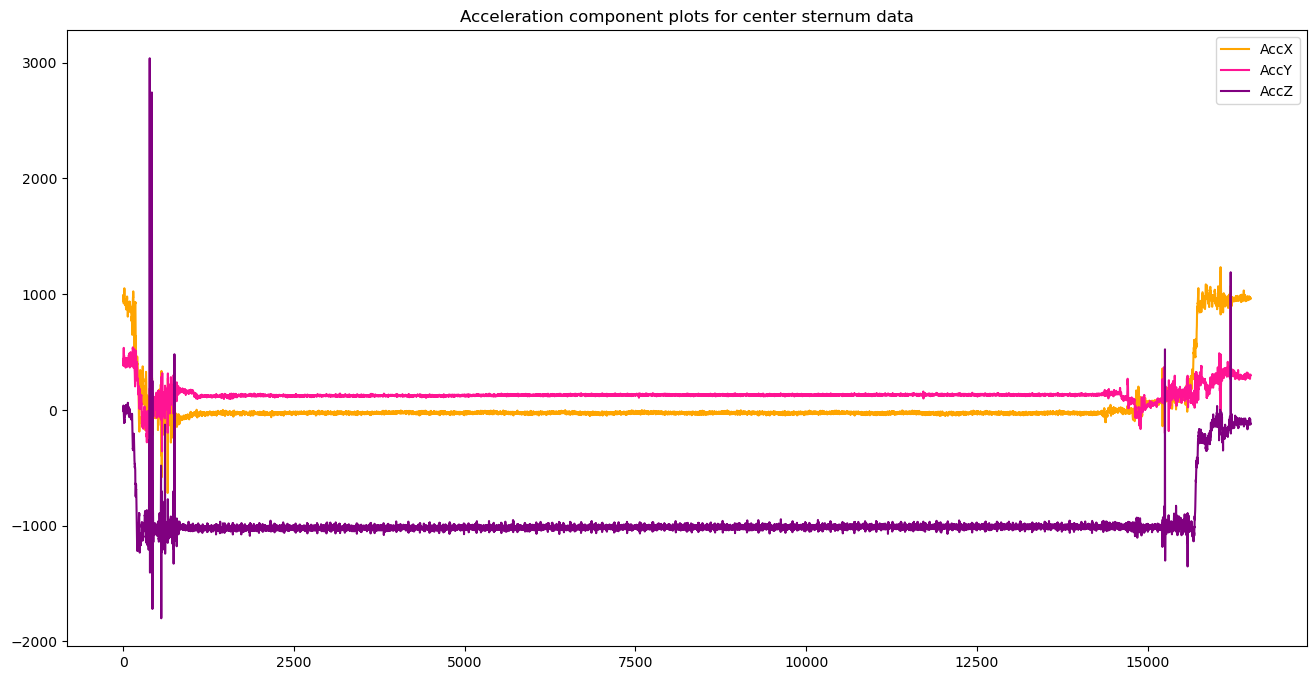

In [11]:
plt.figure(figsize=(16, 8))
plt.plot(cs['AccX'], label='AccX', color=acc_colors[0])
plt.plot(cs['AccY'], label='AccY', color=acc_colors[1])
plt.plot(cs['AccZ'],label='AccZ', color=acc_colors[2])
plt.title('Acceleration component plots for center sternum data')
plt.legend()

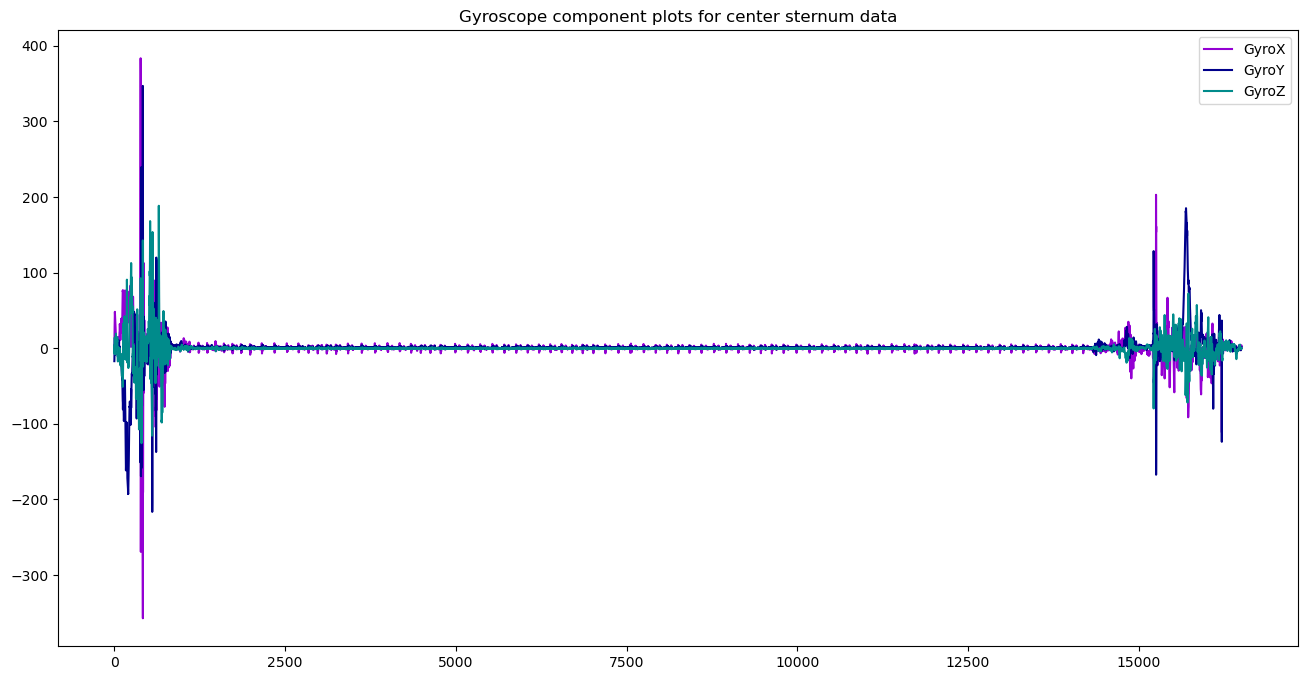

In [12]:
plt.figure(figsize=(16, 8))
plt.plot(cs['GyroX'], label='GyroX', color=gyro_colors[0])
plt.plot(cs['GyroY'], label='GyroY', color=gyro_colors[1])
plt.plot(cs['GyroZ'], label='GyroZ', color=gyro_colors[2])
plt.title('Gyroscope component plots for center sternum data')
plt.legend()

The initial and terminal spikes in the previous plots likely represent motion from when the sensor was first attached and finally removed.

To select an appropriate time window for the analysis, we examine zoomed-in views of each component. This allows us to determine which rows should be discarded.

In the following plots, the first row displays the first N rows of each acceleration/gyroscope component, corresponding to the initial portion of the signal, while the second row shows the last N rows of each component, corresponding to the final portion of the recording. The columns, from left to right, correspond to the X-component, Y-component and Z-component, respectively.

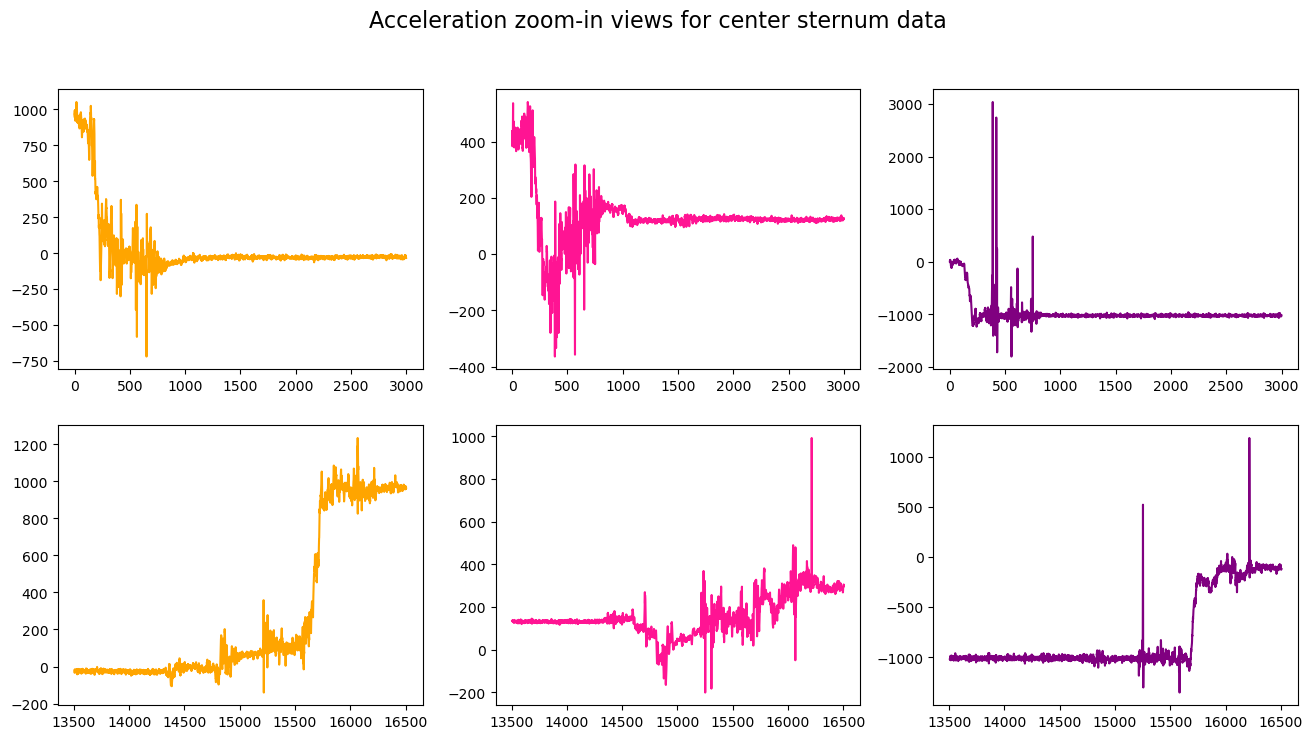

In [13]:
N=3000 # number of rows for the zoom-in views

fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2, 3, figsize=(16, 8))
fig.suptitle('Acceleration zoom-in views for center sternum data', fontsize=16)
ax1.plot(cs["AccX"][:N],color=acc_colors[0])
ax2.plot(cs["AccY"][:N],color=acc_colors[1])
ax3.plot(cs["AccZ"][:N],color=acc_colors[2])

ax4.plot(cs["AccX"][-N:],color=acc_colors[0])
ax5.plot(cs["AccY"][-N:],color=acc_colors[1])
ax6.plot(cs["AccZ"][-N:],color=acc_colors[2])

plt.show()

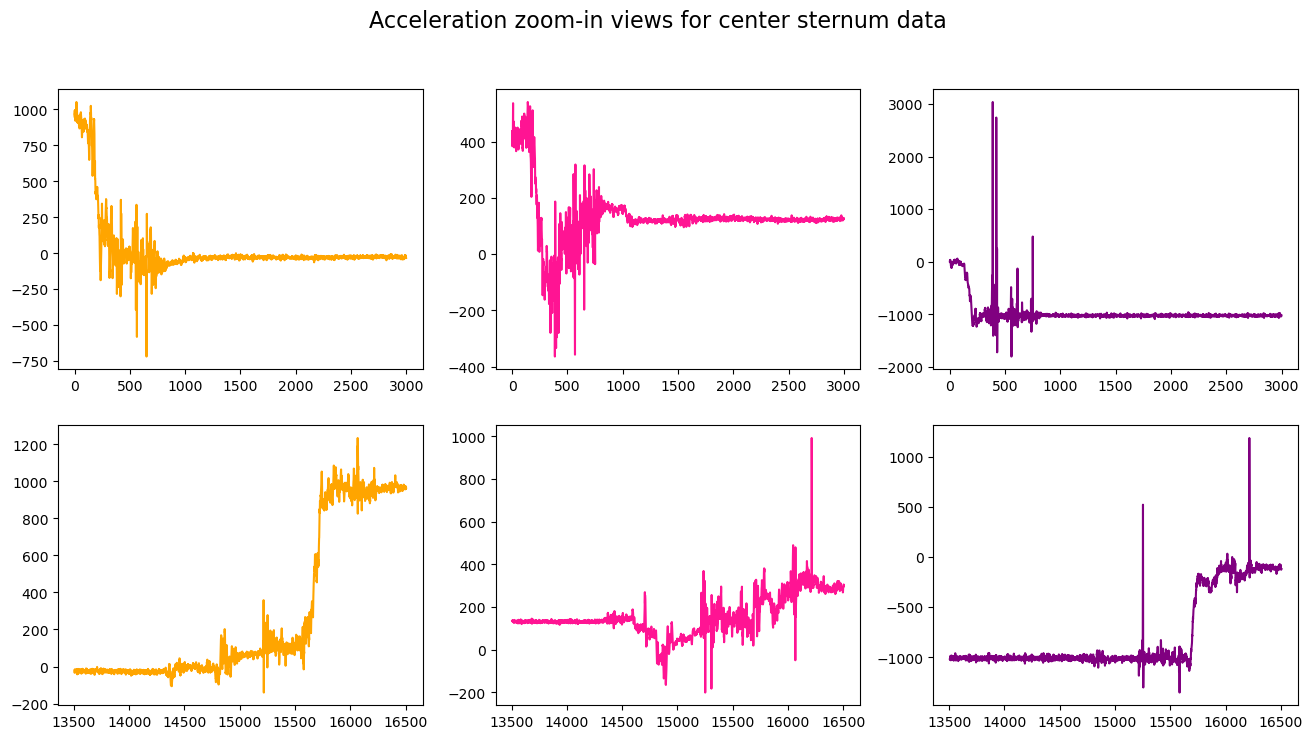

In [14]:
fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2, 3, figsize=(16, 8))
fig.suptitle('Acceleration zoom-in views for center sternum data', fontsize=16)
ax1.plot(cs["AccX"][:N],color=acc_colors[0])
ax2.plot(cs["AccY"][:N],color=acc_colors[1])
ax3.plot(cs["AccZ"][:N],color=acc_colors[2])

ax4.plot(cs["AccX"][-N:],color=acc_colors[0])
ax5.plot(cs["AccY"][-N:],color=acc_colors[1])
ax6.plot(cs["AccZ"][-N:],color=acc_colors[2])

plt.show()

Given the behavior of noise based on these graphs, the data will be analyzed from 1000:-2500 in the Center Sternum dataset.

In [15]:
cs = cs[1000:-3000].copy()

Magnitudes behavior over time

Text(0.5, 1.0, 'Magnitude of Gyroscope')

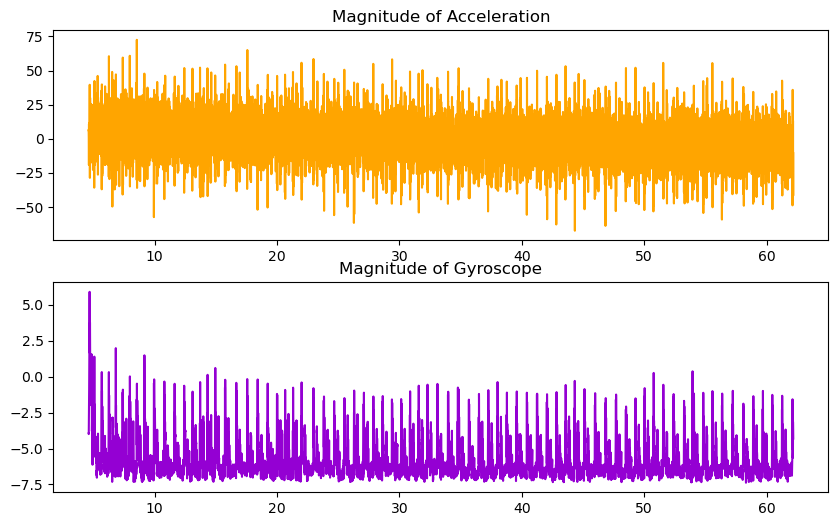

In [16]:
figure, ax = plt.subplots(2, 1, figsize=(10, 6))
ax[0].plot(cs['Time'], cs['MagAcc'], color=acc_colors[0])
ax[0].set_title("Magnitude of Acceleration")

ax[1].plot(cs['Time'], cs['MagGyro'], color=gyro_colors[0])
ax[1].set_title("Magnitude of Gyroscope")

### Statistical Analysis

The **mean** describes the average value of the signal and is useful to understand the general orientation of the sensor relative to gravity. For example, a large constant value in one accelerometer axis usually corresponds to the gravitational component, which indicates the orientation of the sensor on the body.

The **standard deviation** measures the variability of the signal around the mean and is particularly important for SCG/BCG signals because it reflects the amplitude of small vibrations caused by cardiac activity and respiration. 

**Median (50th percentile)** represents the middle of the data distribution, meaning that 50% of the values lie below it and 50% above it. 

**Minimum** and **maximum** also may be important because **minimum** indicates the smallest value of the signal, **maximum** - largest one. These descriptors help to understand the full range of the signal.

**Skewness** measures the asymmetry of the signal distribution, indicating whether values are biased toward higher or lower ranges. This is useful for for SCG/BCG signals because it helps identify asymmetry in the signal caused by physiological activity or motion artifacts. In these signals, heartbeats and sudden movements can create peaks or drops, so skewness helps detect whether the signal is dominated by upward peaks or downward deviations. In other words it shows if the data is balanced or shifted to one side. 

**Kurtosis** describes the presence of extreme values and the “peakedness” of the distribution. High kurtosis indicates more frequent outliers or sharp peaks, which can reflect transient events or noise in the signal.

In [17]:
cols = ['AccX','AccY','AccZ','GyroX','GyroY','GyroZ']

stats = (
    cs[cols]
    .describe()
    .loc[['mean', 'std', '50%', 'min', 'max']]
)

# Add additional statistics
stats.loc['skew'] = cs[cols].skew()
stats.loc['kurtosis'] = cs[cols].kurtosis()

# Round values
stats = stats.round(2)

stats.T

,mean,std,50%,min,max,skew,kurtosis
AccX,-26.63,7.29,-26.52,-65.04,1.82,-0.15,0.44
AccY,127.63,5.94,127.94,95.55,173.04,-0.06,3.35
AccZ,-1014.82,14.68,-1015.19,-1087.59,-944.40,0.14,1.17
GyroX,0.20,1.56,0.10,-8.64,13.14,0.16,6.41
GyroY,0.74,0.76,0.69,-4.69,4.78,0.46,2.40
GyroZ,-0.14,0.43,-0.14,-4.23,2.84,-0.08,6.47


## PCA Analysis

In order to choose the components of accelerometer and gyroscope to work with, we performed a PCA analysis on each measurement.

In [18]:
# PCA for accelerometer

pca_acc = cs[["AccX", "AccY", "AccZ"]]

cov_matrix_acc = pca_acc.cov()
l, v = la.eig(cov_matrix_acc)

percent_variability = l.real * 100 / np.sum(l.real)
indexes = np.argsort(-percent_variability)

for i in percent_variability[indexes]:
    if i > 0.0:
        print(f'{i:.3f}%')
    else:
        print(f'{i:.3e}%')

74.734%
14.667%
10.598%


In [19]:
# PCA for gyroscope

pcc_gyr = cs[["GyroX", "GyroY", "GyroZ"]]

cov_matrix_gyr = pcc_gyr.cov()
l, v = la.eig(cov_matrix_gyr)

percent_variability = l.real * 100 / np.sum(l.real)
indexes = np.argsort(-percent_variability)

for i in percent_variability[indexes]:
    if i > 0.0:
        print(f'{i:.3f}%')
    else:
        print(f'{i:.3e}%')

80.264%
15.259%
4.477%


| Component | Accelerometer (%) | Gyroscope (%) |
|-----------|------------------|--------------|
| PC1       | 74.7             | 80.3         |
| PC2       | 14.7             | 15.3         |
| PC3       | 10.6             | 4.5          |

**For the accelerometer, all three components were retained, as each contributes a meaningful amount of variance. Although the third component of the gyroscope explains less variability, all three components were kept to ensure consistency and allow a more balanced and comparable analysis between the two sensors.**

## Fourier Analysis

Peak frequency: 1.25 Hz
Heart rate: 75.02 bpm
Peak frequency: 1.25 Hz
Heart rate: 75.02 bpm
Peak frequency: 1.25 Hz
Heart rate: 75.02 bpm


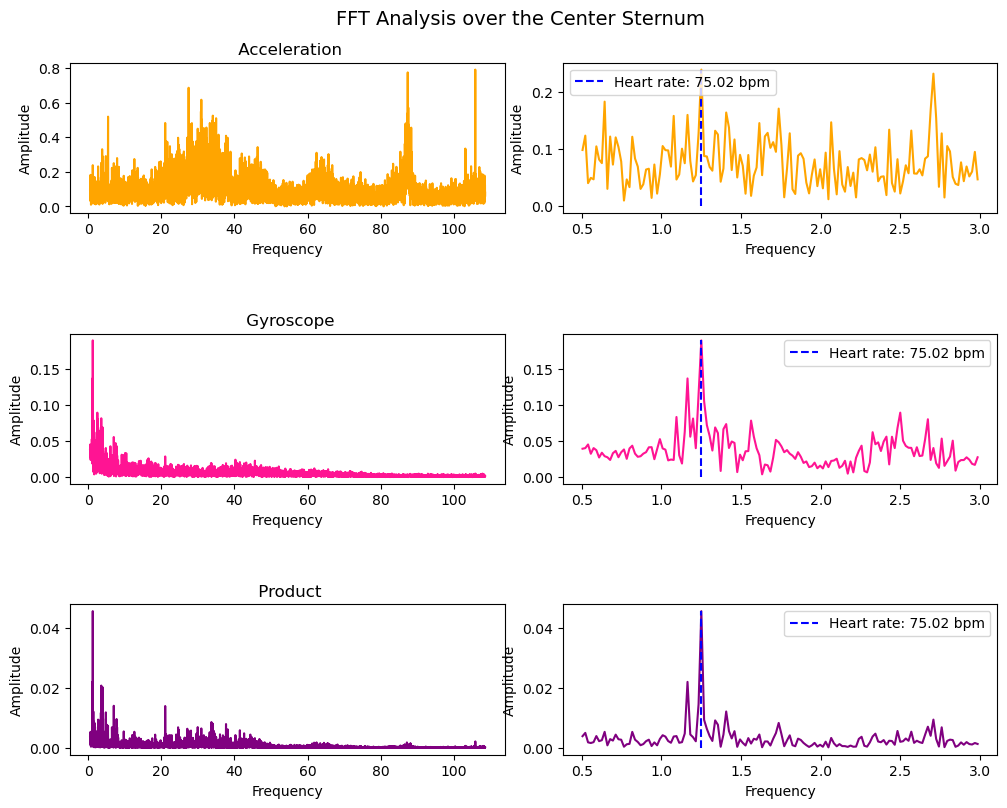

In [20]:
dt = 1/meanfreq_cs

#FFT performance
cs_fft = fft(cs['MagAcc'].values, axis=0, norm="forward")
freqs = fftfreq(np.array(cs['MagAcc']).size, d=dt)

cs_fft_gyro = fft(cs['MagGyro'].values, axis=0, norm="forward")
freqs_gyro = fftfreq(np.array(cs['MagGyro']).size, d=dt)

#mask1 = (freqs > 0.6) & (freqs < 1.6) #taking into account that the normal range is between 40 and 100 bpm
mask = freqs > 0.5
mask1 = (freqs > 0.5) & (freqs < 3.0) # For bpm range of 40 to 120
f_plot = freqs[mask]
p_plot_a = np.abs(cs_fft[mask])
p_plot_g = np.abs(cs_fft_gyro[mask])

#Finding the peaks and the associated bpm
max_idx = [np.argmax(np.abs(cs_fft[mask1])), np.argmax(p_plot_g), np.argmax(p_plot_a*p_plot_g)]
peak_freq = [f_plot[max_idx[0]], f_plot[max_idx[1]], f_plot[max_idx[2]]]
bpm = [freq * 60 for freq in peak_freq]
for i in range(3):
        print(f"Peak frequency: {peak_freq[i]:.2f} Hz")
        print(f"Heart rate: {bpm[i]:.2f} bpm")

#Visualization
fig,ax = plt.subplots(3, 2, figsize=(10, 8))
ax1,ax2,ax3,ax4,ax5,ax6=ax[0,0],ax[0,1],ax[1,0],ax[1,1],ax[2,0],ax[2,1]

fig.suptitle("FFT Analysis over the Center Sternum ", fontsize=14)

ax[0,0].set_title(" Acceleration")
ax[1,0].set_title(" Gyroscope")
ax[2,0].set_title(" Product")

plt.tight_layout()
fig.subplots_adjust(hspace=0.8) 


ax1.plot(f_plot, p_plot_a, color='orange')
ax1.set_xlabel('Frequency')
ax1.set_ylabel('Amplitude')
ax2.plot(freqs[mask1], np.abs(cs_fft[mask1]), color='orange')
ax2.set_xlabel('Frequency')
ax2.set_ylabel('Amplitude')
ax2.vlines(peak_freq[0], ymin=0, ymax=np.abs(cs_fft[mask1][max_idx[0]]), color='blue', linestyle='--',label=f"Heart rate: {bpm[0]:.2f} bpm")

ax2.legend()

ax3.plot(f_plot,p_plot_g,color='deeppink')
ax3.set_xlabel('Frequency')
ax3.set_ylabel('Amplitude')
ax4.plot(freqs[mask1], np.abs(cs_fft_gyro[mask1]), color='deeppink')
ax4.set_xlabel('Frequency')
ax4.set_ylabel('Amplitude')
ax4.vlines(peak_freq[1], ymin=0, ymax=p_plot_g[max_idx[1]], color='blue', linestyle='--',label=f"Heart rate: {bpm[1]:.2f} bpm")

ax4.legend()

ax5.plot(f_plot, p_plot_a*p_plot_g, color='purple')
ax5.set_xlabel('Frequency')
ax5.set_ylabel('Amplitude')
ax6.plot(freqs[mask1], np.abs(cs_fft[mask1])*np.abs(cs_fft_gyro[mask1]), color='purple')
ax6.set_xlabel('Frequency')
ax6.set_ylabel('Amplitude')
ax6.vlines(peak_freq[2], ymin=0, ymax=p_plot_a[max_idx[2]]*p_plot_g[max_idx[2]], color='blue', linestyle='--',label=f"Heart rate: {bpm[2]:.2f} bpm")

ax6.legend()

**The dominant peak in all signals (accelerometer, gyroscope, and their product) is located around 1.2–1.3 Hz. This corresponds to an estimated heart rate of approximately 75 bpm (1.25 Hz × 60 ≈ 75 bpm). This value falls within the expected theoretical resting heart rate range of 40–100 bpm, confirming that the detected peak likely represents the true cardiac activity.**

### Filter implementation 

Initially the implemented filter Butterworth band-pass which takes a determinated range of frequencies and "allow" the pass over it, and outside the range it atuenates the values of the amplitudes. As we are interested in verifying the heart rate previously determinated, its important to only focus in the band between 0.6 Hz and 2.0 Hz

C:\Users\andre\AppData\Local\Temp\ipykernel_10332\1247493806.py:42: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend()


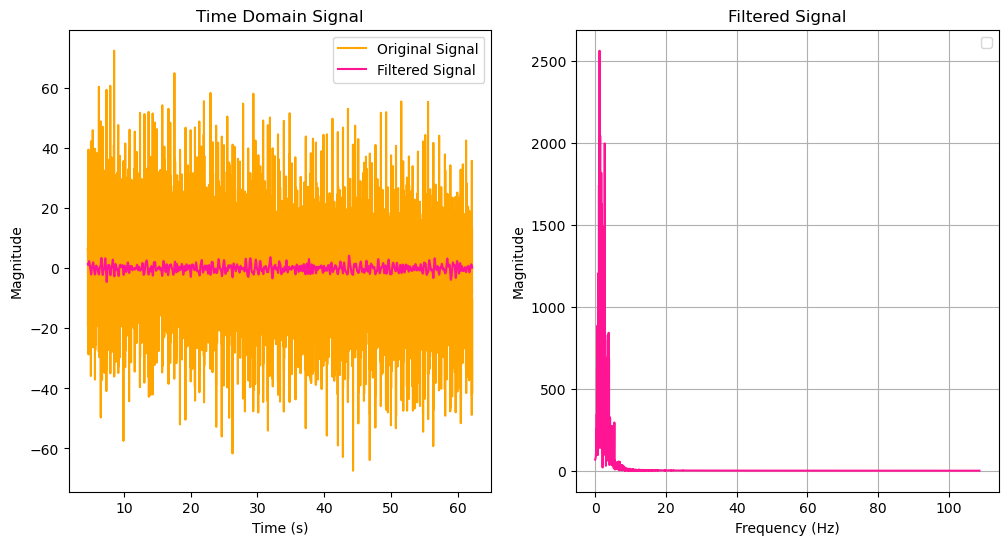

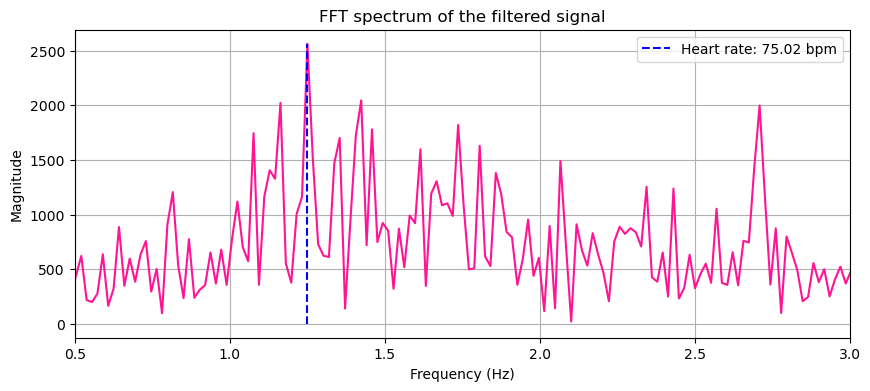

In [21]:
fs = meanfreq_cs       # dataset mean frequency
lowcut = 0.6          # Hz
highcut = 3.0         # Hz

# filter Butterworth bandpass
b_band, a_band = signal.butter(
    N=2,
    Wn=(lowcut, highcut),
    btype="bandpass",
    fs=fs
)

# The input of the filter is the temporal signal, not the FFT, and then we can compare the values 
filtered_signal = signal.filtfilt(b_band, a_band, cs['MagAcc'].values)


# Now performing the FFT on the filtered signal to check if the peak is more evident and if the bpm estimation is more accurate
fft_vals = np.fft.rfft(filtered_signal)
freqs = np.fft.rfftfreq(len(filtered_signal), d=1/fs)

fft_mag = np.abs(fft_vals)


#Visualization
fig, ax = plt.subplots(1,2,figsize=(12, 6))
ax1,ax2=ax[0],ax[1]


ax1.plot(cs['Time'], cs['MagAcc'], label='Original Signal', color='orange')
ax1.plot(cs['Time'], filtered_signal, label='Filtered Signal', color='deeppink')
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Magnitude")
ax1.set_title("Time Domain Signal")
ax1.legend()


ax2.plot(freqs, fft_mag,color='deeppink')

ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Magnitude")
ax2.set_title("Filtered Signal")
ax2.legend()
plt.grid()
plt.show()

plt.figure(figsize=(10,4))
plt.plot(freqs, fft_mag,color='deeppink')
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("FFT spectrum of the filtered signal")
plt.xlim(0.5,3)
max_idx = np.argmax(fft_mag ) 
peak_freq = freqs[max_idx]
bpm = peak_freq * 60
plt.vlines(peak_freq, ymin=0, ymax=np.abs(fft_mag[max_idx]), color='blue', linestyle='--',label=f"Heart rate: {bpm:.2f} bpm")
plt.grid()
plt.legend()
plt.show()

**The analysis was performed using the magnitude of the accelerometer signal. After applying the Butterworth bandpass filter (0.6–3 Hz), the signal becomes significantly cleaner. As a result, the FFT spectrum shows a more pronounced and well-defined peak around 1.25 Hz, corresponding to approximately 75 bpm. This result is consistent with the heart rate estimated before filtering, confirming that the detected peak represents the true cardiac activity while the filtering step improves robustness and clarity.**

## Heart Rate estimation

For finding the distribution of the bpm, we consider to take the difference between the peaks in the filtered signal in the time domain, this, because each peak could be considered as the activity of the heart, in that way the diference can drives us to the estimation of the distribution of the heart rate activity.

As the maximum bpm for a human should be 140bpm, we set the minimum distance between peaks in 0.5s

In [22]:
min_dist = int(fs/2)  # Assuming a minimum heart rate of 40 bpm (0.67 Hz) and a maximum of 120 bpm (2 Hz)

peaks, properties = signal.find_peaks(
    filtered_signal,
    distance=min_dist,
    prominence=np.std(filtered_signal) * 0.3
)


peak_times = cs['Time'].values[peaks]

# Calculate the diference between the peaks
diference = np.diff(peak_times)

# # To convert to bpm 
bpm_inst = 60 / diference

C:\Users\andre\AppData\Local\Temp\ipykernel_10332\3961490039.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


<Figure size 640x480 with 0 Axes>

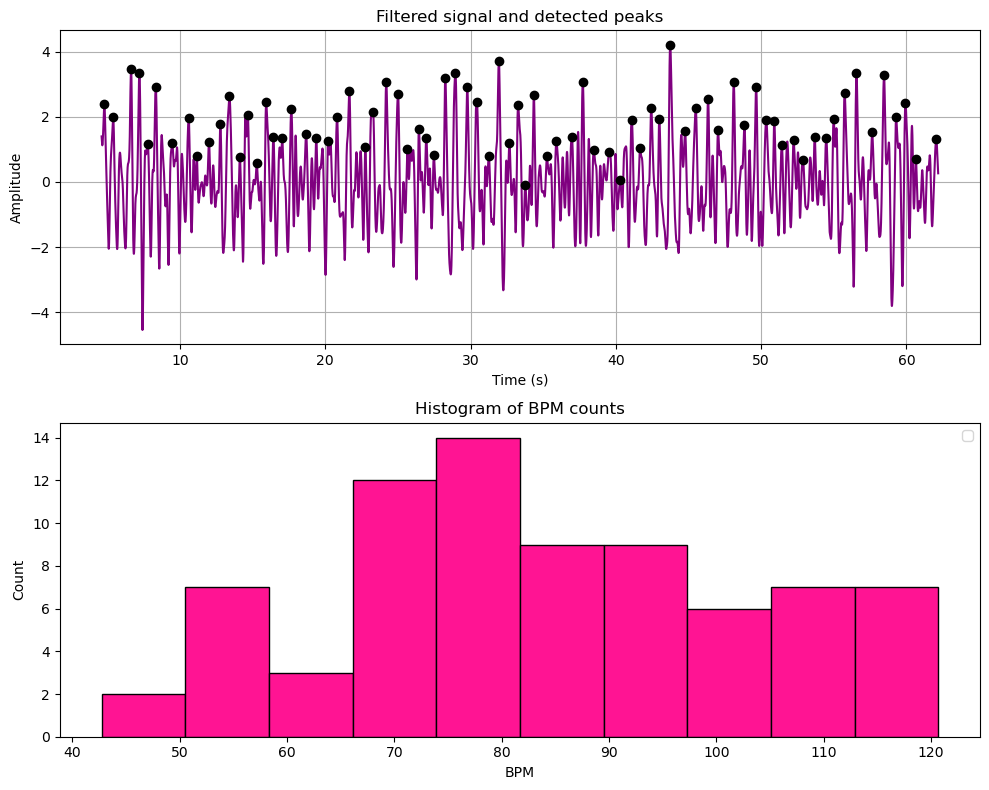

In [23]:
plt.figure()

fig, ax=plt.subplots(2,1, figsize=(10, 8))
ax1, ax2 = ax[0], ax[1]

# Filtered signal with detected peaks
ax1.plot(cs['Time'], filtered_signal, color='purple', label='Filtered signal')
ax1.plot(peak_times, filtered_signal[peaks], 'o', color='black', label='Peaks')
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Amplitude")
ax1.set_title("Filtered signal and detected peaks")
ax1.grid()
ax2.hist(bpm_inst, bins=10, color='deeppink',edgecolor='black')
ax2.set_xlabel("BPM")
ax2.set_ylabel("Count")
ax2.set_title("Histogram of BPM counts")



plt.legend()
plt.tight_layout()

In [24]:
print("Mean BPM:", np.mean(bpm_inst))
print("Std BPM:", np.std(bpm_inst))
print("Min BPM:", np.min(bpm_inst))
print("Max BPM:", np.max(bpm_inst))

Mean BPM: 84.17620207727418
Std BPM: 18.95446009629543
Min BPM: 42.724762726488464
Max BPM: 120.65789473684279


As the HRV 

Text(0, 0.5, 'Frequency')

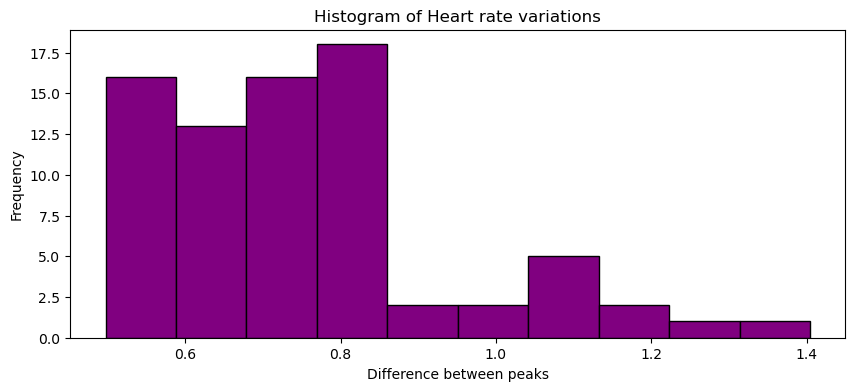

In [25]:
plt.figure(figsize=(10,4))
plt.hist(diference, bins=10, color='purple', edgecolor='black')
plt.title("Histogram of Heart rate variations")
plt.xlabel("Difference between peaks")
plt.ylabel("Frequency")

**The BPM histogram shows that most values are concentrated around 70–90 bpm, consistent with previous estimates. For the HRV histogram, the values are not too spread out, which means the heart rhythm is quite stable with small natural variations. This is normal for a healthy heart..**

# 2. Other Datasets

## Importing
* 1_Stave_supine_static (ss
  
* 2_Mattress_supin (ms)

* 3_Subject_sitting_cha (sc)
  
* 4_Chest_swea (ch)

* 5_Under_c (uc)txt:

In [26]:
file_names = [
    "1_Stave_supine_static.txt",
    "2_Mattress_supine.txt",
    "3_Subject_sitting_chair.txt",
    "4_Chest_sweater.txt",
    "5_Under_chair.txt"
]

datasets = {}

for i, file in enumerate(file_names, start=1):
    datasets[i] = pd.read_csv(file, sep='\t')

## Calibration of all datasets

This dataset is regarding the first healthy person.

Configuration:	4000 dps, 2 g, 12 G, 100 g, High Resolution, sampling rate = 100 Hz

Date: 16-17/04/2019 

Accelerometer/Gyroscope calibration matrix:

In [27]:
gyro_cali = np.array([-2.804399,	1.793105,	0.3411708])

acc_cali = np.array([[1.002982,9.415505E-05,0.004346743],
[9.04459E-05,1.002731,-0.001444198],
[0.004346536,-0.001444751,1.030587]])

acc_offset = np.array([3.602701,-20.96658, 54.97186])

In [28]:
for i in range(1,6):
    acc_raw = datasets[i][['AccX','AccY','AccZ']].values
    acc_corrected = (acc_raw - acc_offset[0])@acc_cali.T
    datasets[i][['AccX','AccY','AccZ']] = acc_corrected

    gyro_raw = datasets[i][['GyroX','GyroY','GyroZ']].values
    gyro_corrected = gyro_raw - gyro_cali
    datasets[i][['GyroX','GyroY','GyroZ']] = gyro_corrected
datasets[1].head()

,Log Mode,Log Freq,Timestamp,AccX,AccY,AccZ,GyroX,GyroY,GyroZ,MagnX,MagnY,MagnZ,qw,qi,qj,qk
0,5,100,1555487493,491.992244,304.203924,887.388305,-37.927311,29.182505,45.512489,-642,-90,-83,0.182482,0.375561,0.139683,0.897855
1,5,100,1555487493,33.415889,225.710378,1042.549677,26.706839,23.816655,40.390539,-177,-185,-321,0.910500,0.099033,0.037385,0.399731
2,5,100,1555487493,37.441764,251.833722,1039.071926,-18.659021,1.987383,10.878339,-179,-185,-325,0.881061,0.112613,0.042390,0.457442
3,5,100,1555487493,66.324307,236.787319,1040.664665,-27.439501,9.426405,6.000293,-180,-185,-325,0.877629,0.112827,0.042695,0.463912
4,5,100,1555487493,20.153475,246.277459,1030.832622,-32.927311,11.133725,0.634439,-178,-182,-328,0.876462,0.111820,0.042726,0.466353


### Time treatment

In [29]:
for i in range(1,6):
    counts_ds = datasets[i].groupby('Timestamp').size()
    datasets[i]['Time'] = np.arange(0,len(datasets[i]['Timestamp']))/counts_ds.mean()
datasets[1].head()


,Log Mode,Log Freq,Timestamp,AccX,AccY,AccZ,GyroX,GyroY,GyroZ,MagnX,MagnY,MagnZ,qw,qi,qj,qk,Time
0,5,100,1555487493,491.992244,304.203924,887.388305,-37.927311,29.182505,45.512489,-642,-90,-83,0.182482,0.375561,0.139683,0.897855,0.000000
1,5,100,1555487493,33.415889,225.710378,1042.549677,26.706839,23.816655,40.390539,-177,-185,-321,0.910500,0.099033,0.037385,0.399731,0.010033
2,5,100,1555487493,37.441764,251.833722,1039.071926,-18.659021,1.987383,10.878339,-179,-185,-325,0.881061,0.112613,0.042390,0.457442,0.020065
3,5,100,1555487493,66.324307,236.787319,1040.664665,-27.439501,9.426405,6.000293,-180,-185,-325,0.877629,0.112827,0.042695,0.463912,0.030098
4,5,100,1555487493,20.153475,246.277459,1030.832622,-32.927311,11.133725,0.634439,-178,-182,-328,0.876462,0.111820,0.042726,0.466353,0.040131


### Magnitudes calculation

In [30]:
for i, file in enumerate(file_names, start=1):
    datasets[i]['MagAcc']=np.sqrt(datasets[i]['AccX']**2 + datasets[i]['AccY']**2 + datasets[i]['AccZ']**2)
    datasets[i]['MagAcc']=datasets[i]['MagAcc']-datasets[i]['MagAcc'].mean()
    datasets[i]['MagGyro']=np.sqrt(datasets[i]['GyroX']**2+datasets[i]['GyroY']**2+datasets[i]['GyroZ']**2)
    datasets[i]['MagGyro']=datasets[i]['MagGyro']-datasets[i]['MagGyro'].mean()
datasets[1].head()

,Log Mode,Log Freq,Timestamp,AccX,AccY,AccZ,GyroX,GyroY,GyroZ,MagnX,MagnY,MagnZ,qw,qi,qj,qk,Time,MagAcc,MagGyro
0,5,100,1555487493,491.992244,304.203924,887.388305,-37.927311,29.182505,45.512489,-642,-90,-83,0.182482,0.375561,0.139683,0.897855,0.000000,84.765332,41.084641
1,5,100,1555487493,33.415889,225.710378,1042.549677,26.706839,23.816655,40.390539,-177,-185,-321,0.910500,0.099033,0.037385,0.399731,0.010033,92.720777,29.004968
2,5,100,1555487493,37.441764,251.833722,1039.071926,-18.659021,1.987383,10.878339,-179,-185,-325,0.881061,0.112613,0.042390,0.457442,0.020065,95.304239,-3.267117
3,5,100,1555487493,66.324307,236.787319,1040.664665,-27.439501,9.426405,6.000293,-180,-185,-325,0.877629,0.112827,0.042695,0.463912,0.030098,94.816899,4.670560
4,5,100,1555487493,20.153475,246.277459,1030.832622,-32.927311,11.133725,0.634439,-178,-182,-328,0.876462,0.111820,0.042726,0.466353,0.040131,85.529849,9.807588


In [31]:
for i in range(1,6):
    datasets[i]=datasets[i][1000:-3000].copy()

## General Exploratory Data Analysis to choose one of the datasets

Plotting all of the acceleration magnitudes over time to compare the behavior

We decided to choose the dataset according to the one that presented better data in terms of less noise and smooth standard deviation/mean.

Ploting all of the acceleration magnitudes over time to compare the behavior

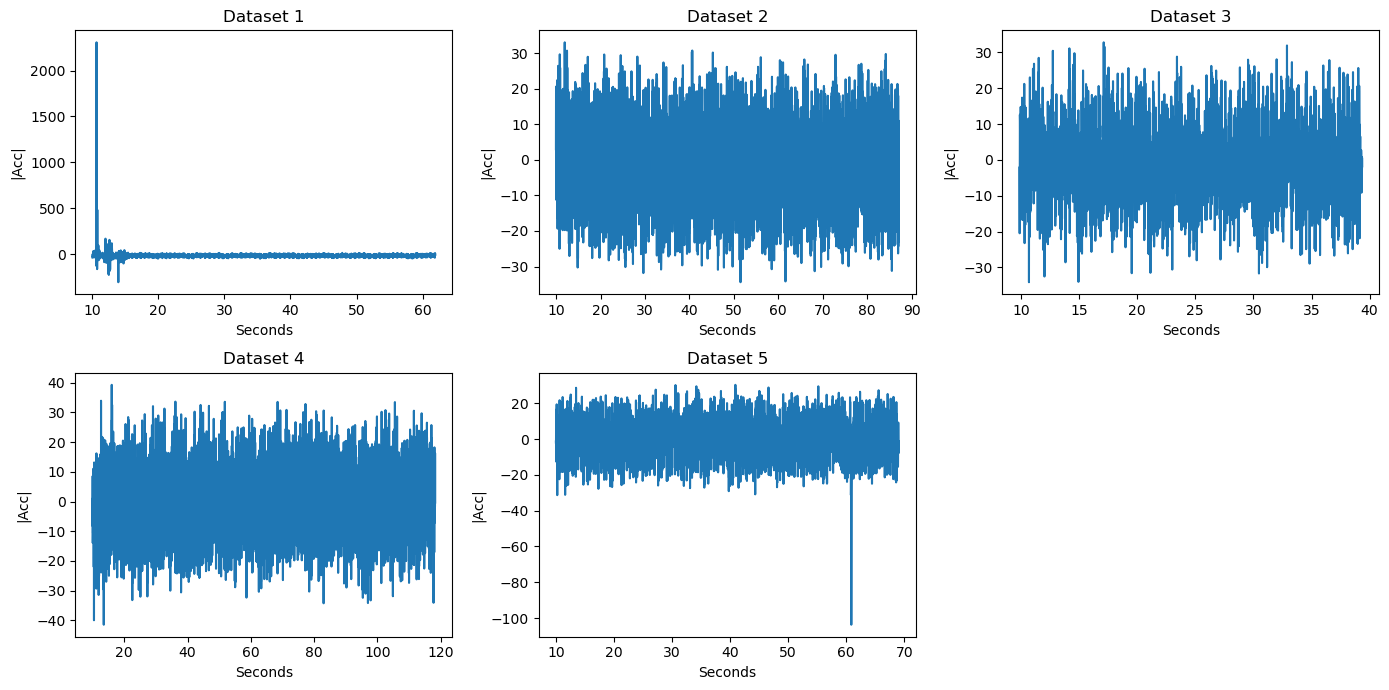

In [32]:
all_datasets = [datasets[i] for i in range(1,6)]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()

titles = [f'Dataset {i}' for i in range(1,6)]

for i, df in enumerate(all_datasets):
    
    axes[i].plot(df['Time'], df['MagAcc'])
    axes[i].set_title(titles[i])
    axes[i].set_xlabel('Seconds')
    axes[i].set_ylabel('|Acc|')
fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

Looking at the behavior of the Acceleration Magnitude: 
* Dataset 1 has a lot of noise, indicating that the collected data is not very accurate and, furthermore, it would be necessary to remove a large part of the sample. The same is observed in Dataset 2, besides there's more data points
* Dataset 5 presents a random peak, representing that maybe it can depend too much on the position of the person, which affects the quality of the data collected.

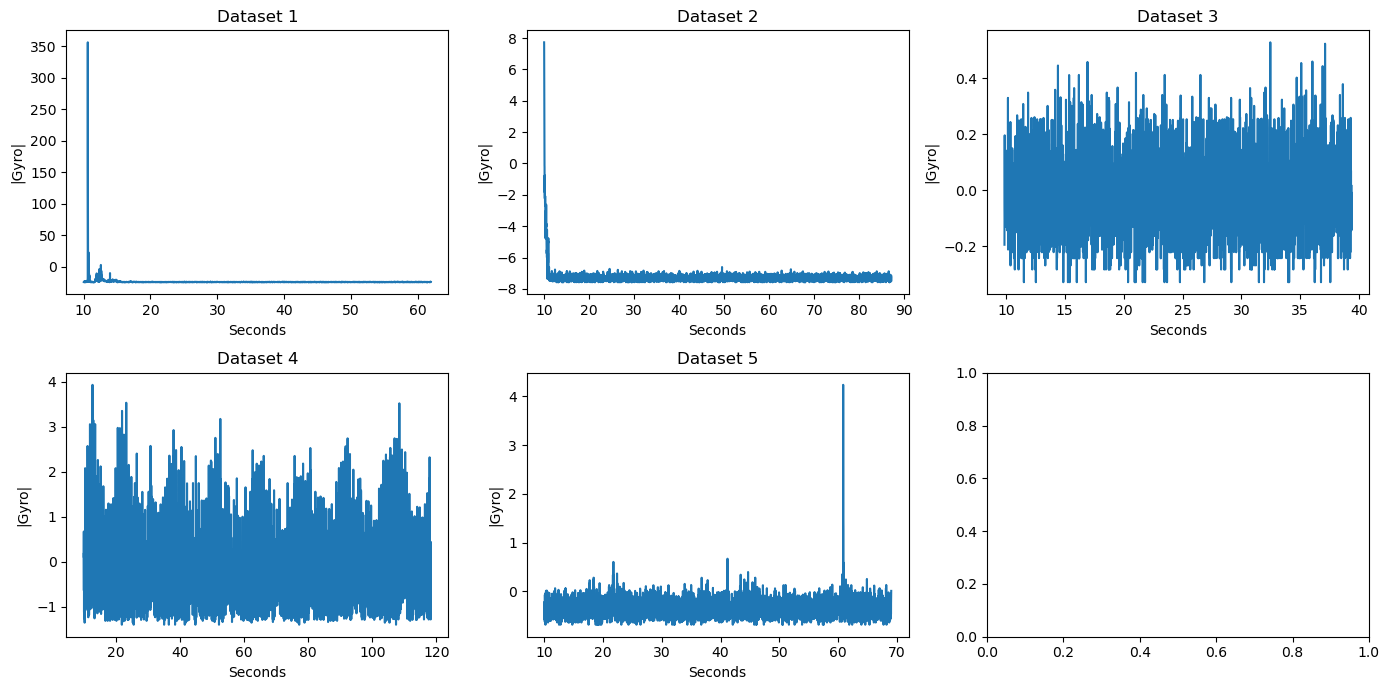

In [33]:
#ploting all of the gyro magnitudes over time to compare the behavior
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.flatten()

titles = [f'Dataset {i}' for i in range(1,6)]

for i, df in enumerate(all_datasets):
    
    axes[i].plot(df['Time'], df['MagGyro'])
    axes[i].set_title(titles[i])
    axes[i].set_xlabel('Seconds')
    axes[i].set_ylabel('|Gyro|')

plt.tight_layout()
plt.show()

For the Gyroscope magnitude: we can observe the same behavior as with the accelerator.

Now, deccomposing the acceleration and gyroscope components over all the datasets, to observe if there's any component presenting too much noise.

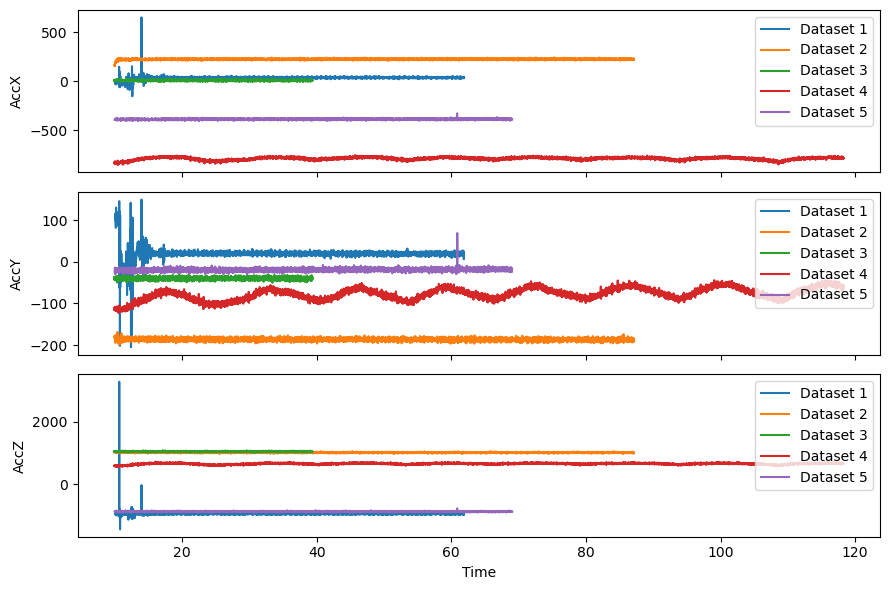

In [34]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(3, 1, figsize=(9, 6), sharex=True)  

# AccX
axs[0].plot(datasets[1]['Time'], datasets[1]['AccX'], label='Dataset 1')
axs[0].plot(datasets[2]['Time'], datasets[2]['AccX'], label='Dataset 2')
axs[0].plot(datasets[3]['Time'], datasets[3]['AccX'], label='Dataset 3')
axs[0].plot(datasets[4]['Time'], datasets[4]['AccX'], label='Dataset 4')
axs[0].plot(datasets[5]['Time'], datasets[5]['AccX'], label='Dataset 5')
axs[0].set_ylabel('AccX')
axs[0].legend()

# AccY
axs[1].plot(datasets[1]['Time'], datasets[1]['AccY'], label='Dataset 1')
axs[1].plot(datasets[2]['Time'], datasets[2]['AccY'], label='Dataset 2')
axs[1].plot(datasets[3]['Time'], datasets[3]['AccY'], label='Dataset 3')
axs[1].plot(datasets[4]['Time'], datasets[4]['AccY'], label='Dataset 4')
axs[1].plot(datasets[5]['Time'], datasets[5]['AccY'], label='Dataset 5')
axs[1].set_ylabel('AccY')
axs[1].legend()

# AccZ
axs[2].plot(datasets[1]['Time'], datasets[1]['AccZ'], label='Dataset 1')
axs[2].plot(datasets[2]['Time'], datasets[2]['AccZ'], label='Dataset 2')
axs[2].plot(datasets[3]['Time'], datasets[3]['AccZ'], label='Dataset 3')
axs[2].plot(datasets[4]['Time'], datasets[4]['AccZ'], label='Dataset 4')
axs[2].plot(datasets[5]['Time'], datasets[5]['AccZ'], label='Dataset 5')
axs[2].set_ylabel('AccZ')
axs[2].set_xlabel('Time')
axs[2].legend()

plt.tight_layout() 
plt.show()

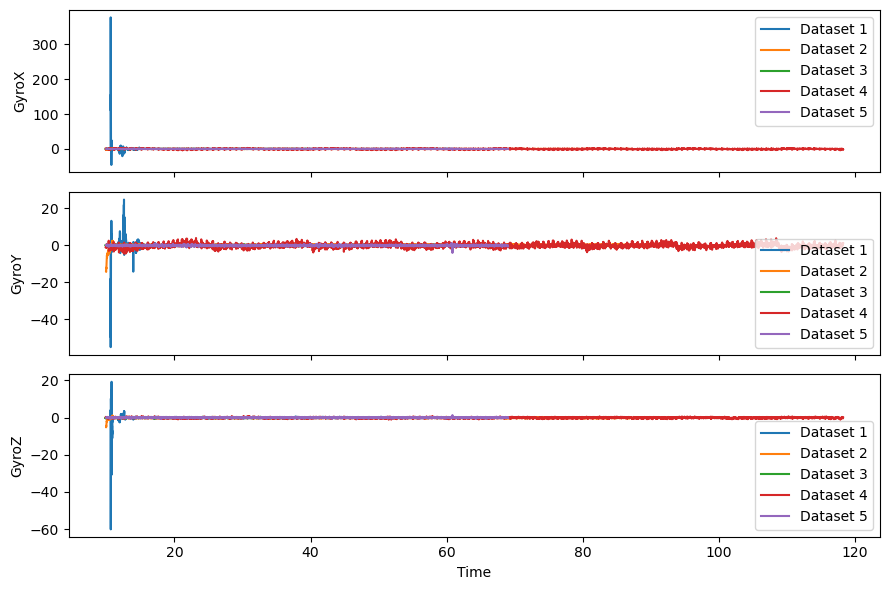

In [35]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(3, 1, figsize=(9, 6), sharex=True) 

axs[0].plot(datasets[1]['Time'], datasets[1]['GyroX'], label='Dataset 1')
axs[0].plot(datasets[2]['Time'], datasets[2]['GyroX'], label='Dataset 2')
axs[0].plot(datasets[3]['Time'], datasets[3]['GyroX'], label='Dataset 3')
axs[0].plot(datasets[4]['Time'], datasets[4]['GyroX'], label='Dataset 4')
axs[0].plot(datasets[5]['Time'], datasets[5]['GyroX'], label='Dataset 5')
axs[0].set_ylabel('GyroX')
axs[0].legend()

axs[1].plot(datasets[1]['Time'], datasets[1]['GyroY'], label='Dataset 1')
axs[1].plot(datasets[2]['Time'], datasets[2]['GyroY'], label='Dataset 2')
axs[1].plot(datasets[3]['Time'], datasets[3]['GyroY'], label='Dataset 3')
axs[1].plot(datasets[4]['Time'], datasets[4]['GyroY'], label='Dataset 4')
axs[1].plot(datasets[5]['Time'], datasets[5]['GyroY'], label='Dataset 5')
axs[1].set_ylabel('GyroY')
axs[1].legend()

axs[2].plot(datasets[1]['Time'], datasets[1]['GyroZ'], label='Dataset 1')
axs[2].plot(datasets[2]['Time'], datasets[2]['GyroZ'], label='Dataset 2')
axs[2].plot(datasets[3]['Time'], datasets[3]['GyroZ'], label='Dataset 3')
axs[2].plot(datasets[4]['Time'], datasets[4]['GyroZ'], label='Dataset 4')
axs[2].plot(datasets[5]['Time'], datasets[5]['GyroZ'], label='Dataset 5')
axs[2].set_ylabel('GyroZ')
axs[2].set_xlabel('Time')
axs[2].legend()

plt.tight_layout()  # Ajusta os subplots para não sobrepor
plt.show()

Calculating the standard deviation:

In [36]:
all_datasets = {}

for i in range(1,6):
    all_datasets[f'Dataset_{i}'] = datasets[i]

results = []

for name, df in all_datasets.items():
    
    std_acc = df['MagAcc'].std()
    std_gyro = df['MagGyro'].std()
    mean_acc = df['MagAcc'].mean()
    mean_gyro = df['MagGyro'].mean()
    var_coef_acc = np.std(df['MagAcc']) / np.mean(df['MagAcc'])
    var_coef_gyro = np.std(df['MagGyro']) / np.mean(df['MagGyro'])
    
    results.append([name, std_acc, std_gyro, mean_acc, mean_gyro,var_coef_acc,var_coef_gyro])

df_comparison = pd.DataFrame(results,
                      columns=['Dataset','STD_MagAcc','STD_MagGyro','Mean_MagAcc','Mean_MagGyro','VarCoef_MagAcc','VarCoef_MagGyro'])

df_comparison

,Dataset,STD_MagAcc,STD_MagGyro,Mean_MagAcc,Mean_MagGyro,VarCoef_MagAcc,VarCoef_MagGyro
0,Dataset_1,36.912900,6.740335,-17.172170,-24.134557,-2.149369,-0.279254
1,Dataset_2,10.206399,0.562839,-1.338983,-7.272710,-7.622006,-0.077385
2,Dataset_3,10.563943,0.144222,-0.301524,-0.016284,-35.029321,-8.854962
3,Dataset_4,9.501332,0.697327,-0.085675,-0.338106,-110.894403,-2.062357
4,Dataset_5,9.775303,0.180715,-0.175092,-0.342087,-55.824798,-0.528228


With these information, we infere:

* Dataset 1 and 2: they show a very high deviation, indicating the low accuracy of the data and much interference of noise.

* Dataset 3: data can be too smoothed, and has a higher variation coefficient then Dataset 4.

* Dataset 5: shows peaks when data should be 'stable', that means that it can depend too much on the position of the person.

* Dataset 4 shows the smaller standard deviation in acceleration, while still showing a good stantard deviation in gyroscope. Given that, we will proceed with the Dataset 4 - Chest Sweater.

# 3. Dataset 4 - Chest Sweater

## Statistical Analysis

We now perform the statistical analysis for the second dataset. As a reminder, the main features we want to consider is mean, standard deviation, median, minimum and maximum, skewness and kurtosis. The same set of statistical descriptors is computed to ensure consistency and allow comparison between datasets.

In [37]:
ch = datasets[2].copy()

cols4 = ['AccX','AccY','AccZ','GyroX','GyroY','GyroZ']

stats4 = (
    ch[cols]
    .describe()
    .loc[['mean', 'std', '50%', 'min', 'max']]
)

# Add additional statistics
stats4.loc['skew'] = cs[cols].skew()
stats4.loc['kurtosis'] = cs[cols].kurtosis()

# Round values
stats4 = stats4.round(2)

stats4.T

,mean,std,50%,min,max,skew,kurtosis
AccX,223.80,5.53,223.98,151.33,242.85,-0.15,0.44
AccY,-186.55,3.10,-186.53,-199.46,-168.36,-0.06,3.35
AccZ,1009.93,10.69,1009.90,972.73,1046.83,0.14,1.17
GyroX,0.07,0.20,0.12,-2.56,2.19,0.16,6.41
GyroY,-0.12,0.57,-0.09,-14.48,2.35,0.46,2.40
GyroZ,-0.06,0.22,-0.10,-5.10,1.12,-0.08,6.47


## PCA Analysis

In [38]:
# PCA for accelerometer

pca_acc = ch[["AccX", "AccY", "AccZ"]]

cov_matrix_acc = pca_acc.cov()
l, v = la.eig(cov_matrix_acc)

percent_variability = l.real * 100 / np.sum(l.real)
indexes = np.argsort(-percent_variability)

for i in percent_variability[indexes]:
    if i > 0.0:
        print(f'{i:.3f}%')
    else:
        print(f'{i:.3e}%')

74.245%
19.599%
6.156%


In [39]:
# PCA for gyroscope

pcc_gyr = ch[["GyroX", "GyroY", "GyroZ"]]

cov_matrix_gyr = pcc_gyr.cov()
l, v = la.eig(cov_matrix_gyr)

percent_variability = l.real * 100 / np.sum(l.real)
indexes = np.argsort(-percent_variability)

for i in percent_variability[indexes]:
    if i > 0.0:
        print(f'{i:.3f}%')
    else:
        print(f'{i:.3e}%')

86.132%
8.040%
5.828%


| Component | Accelerometer (%) | Gyroscope (%) |
|-----------|------------------|--------------|
| PC1       | 74.3             | 86.1         |
| PC2       | 19.6             | 8.0          |
| PC3       | 6.2              | 5.8          |

## Exploratory Analysis

### Correlation matrix
To understant if it would be possible to eliminate of of the components (of the acceleration or gyroscope measurements)

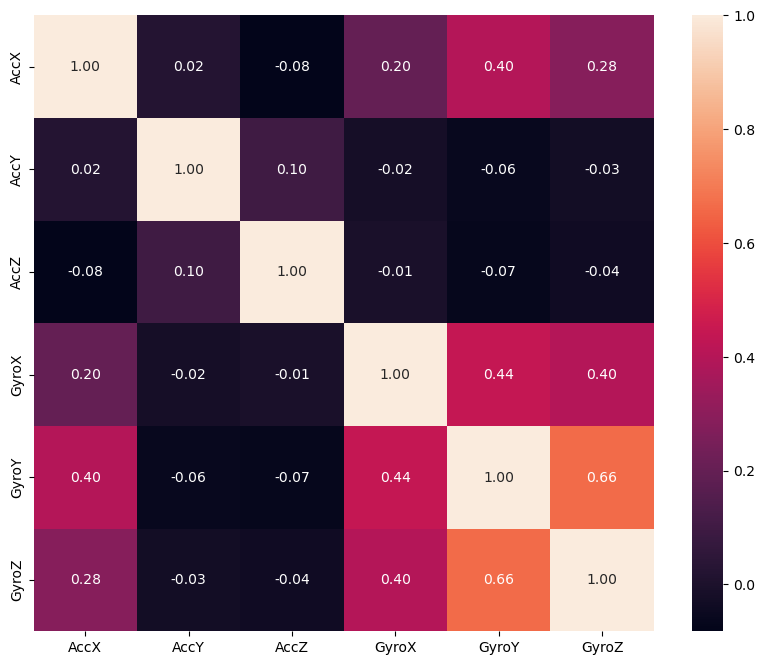

In [40]:
cols = ['AccX','AccY',	'AccZ',	'GyroX',	'GyroY',	'GyroZ']
        #,	'MagnX',	'MagnY',	'MagnZ',	'qw',	'qi',	'qj',	'qk']
corr_matrix = ch[cols].corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f',cmap="rocket",annot_kws={"size":10})
plt.show()

### Time distribution

Text(0.5, 1.0, 'Magnitude of Gyroscope')

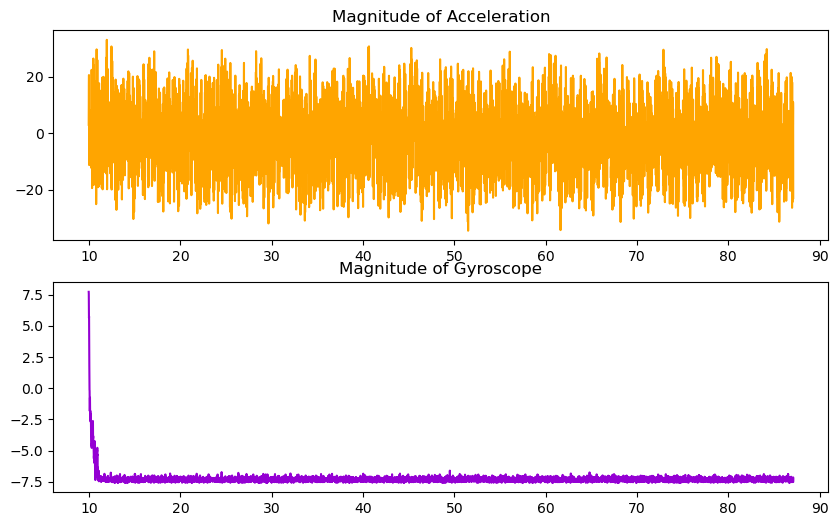

In [41]:
figure, ax = plt.subplots(2, 1, figsize=(10, 6))
ax[0].plot(ch['Time'], ch['MagAcc'], color=acc_colors[0])
ax[0].set_title("Magnitude of Acceleration")

ax[1].plot(ch['Time'], ch['MagGyro'], color=gyro_colors[0])
ax[1].set_title("Magnitude of Gyroscope")

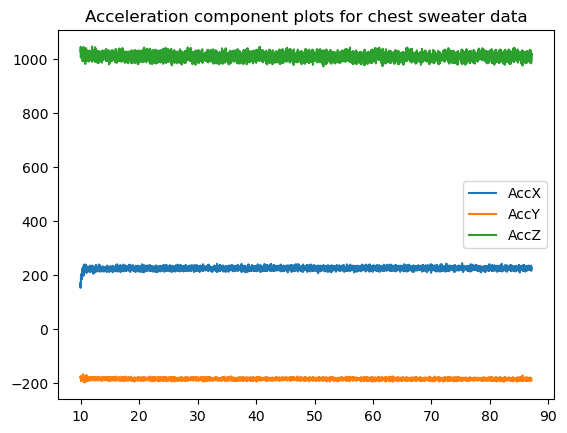

In [42]:
#Behavior of acceleration components of chest sweater over time
plt.plot(ch['Time'], ch['AccX'], label='AccX')
plt.plot(ch['Time'], ch['AccY'], label='AccY')
plt.plot(ch['Time'], ch['AccZ'], label='AccZ')
plt.title('Acceleration component plots for chest sweater data')
plt.legend()

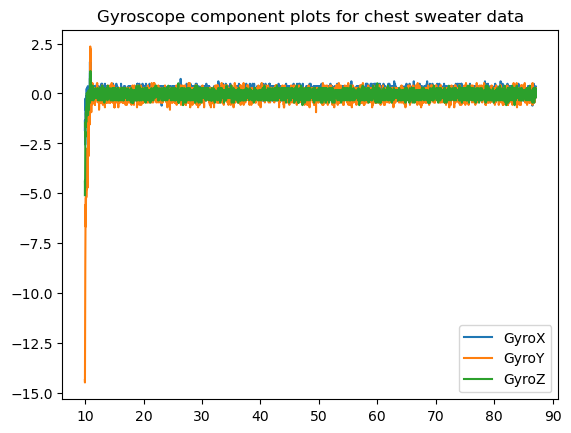

In [43]:
#Behavior of gyroscope components of chest sweater over time
plt.plot(ch['Time'], ch['GyroX'], label='GyroX')
plt.plot(ch['Time'], ch['GyroY'], label='GyroY')
plt.plot(ch['Time'], ch['GyroZ'], label='GyroZ')
plt.title('Gyroscope component plots for chest sweater data')
plt.legend()

## Fourier Analysis

In [44]:
#Sliced dataset - to cut the noise
ch = ch[1000:-1000].copy()
ch

,Log Mode,Log Freq,Timestamp,AccX,AccY,AccZ,GyroX,GyroY,GyroZ,MagnX,MagnY,MagnZ,qw,qi,qj,qk,Time,MagAcc,MagGyro
2000,5,100,1555488218,224.707849,-186.968480,1003.991608,0.121472,0.036163,0.146634,-436,410,-341,0.474935,-0.138005,0.017640,-0.868954,19.921675,-6.794757,-7.421801
2001,5,100,1555488218,231.885378,-181.754573,993.956874,0.243423,-0.451642,0.024683,-437,410,-341,0.474907,-0.138493,0.017579,-0.868892,19.931636,-15.772035,-7.101959
2002,5,100,1555488218,216.311767,-188.126732,1000.625071,0.365375,0.158115,0.146634,-437,410,-342,0.474915,-0.138462,0.017609,-0.868892,19.941597,-11.595475,-7.191352
2003,5,100,1555488218,227.805315,-182.148641,1012.987713,0.365375,0.280066,0.024683,-436,410,-341,0.474929,-0.138218,0.017640,-0.868923,19.951558,1.666672,-7.154591
2004,5,100,1555488218,230.802815,-185.798010,998.484257,0.121472,0.158115,0.024683,-437,410,-340,0.474944,-0.138188,0.017457,-0.868923,19.961519,-10.957428,-7.414706
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7741,5,100,1555488275,218.731212,-185.935531,1008.490465,0.243423,-0.329690,-0.219220,-438,411,-341,0.474522,-0.139256,0.017426,-0.868984,77.106845,-3.920964,-7.150851
7742,5,100,1555488275,225.150637,-187.707285,1007.452141,0.243423,0.036163,-0.219220,-438,411,-344,0.474494,-0.139531,0.017518,-0.868954,77.116806,-3.244886,-7.286042
7743,5,100,1555488275,223.687649,-186.914014,1008.701948,0.121472,0.158115,0.024683,-438,410,-341,0.474458,-0.139439,0.017701,-0.868984,77.126767,-2.498899,-7.414706
7744,5,100,1555488275,221.297619,-189.298493,1007.814924,0.121472,-0.085788,-0.219220,-438,411,-340,0.474417,-0.139561,0.017823,-0.868984,77.136727,-3.430359,-7.350717


Peak frequency: 0.52 Hz
Heart rate: 31.03 bpm
Peak frequency: 1.38 Hz
Heart rate: 82.76 bpm
Peak frequency: 1.38 Hz
Heart rate: 82.76 bpm


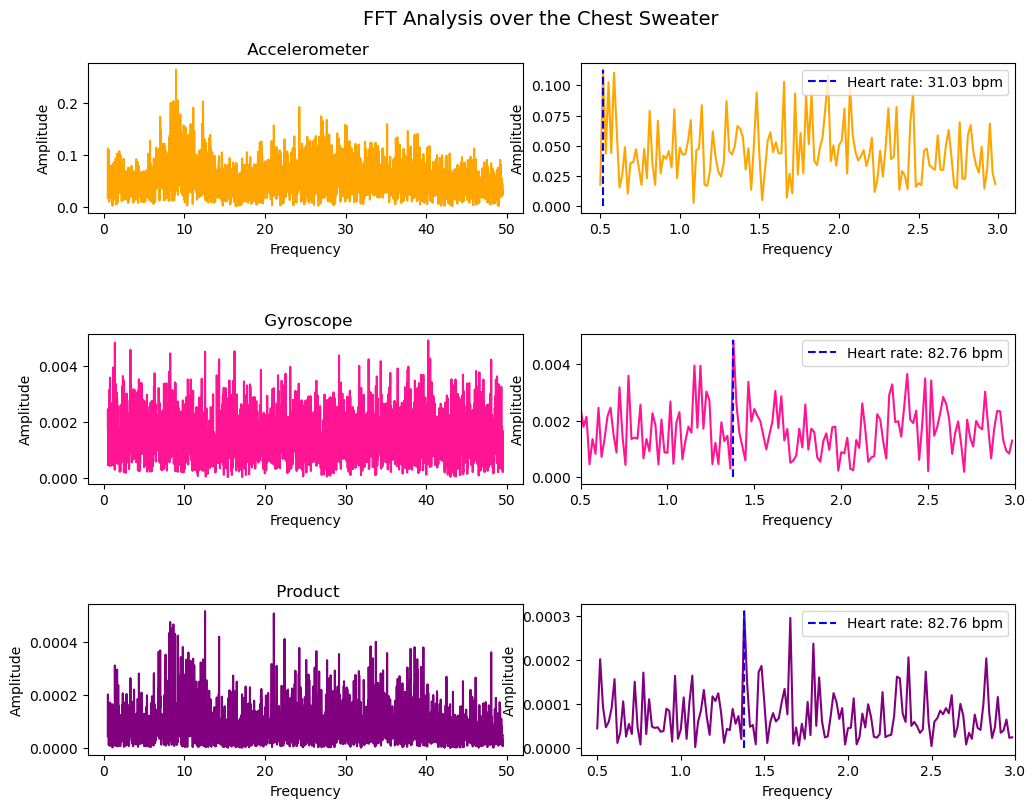

In [50]:
#Time setting
meanfreq_ch = ch['Timestamp'].value_counts().mean()
dt = 1/meanfreq_ch

#FFT performance
ch_fft = fft(ch['AccX'].values, axis=0, norm="forward")
freqs = fftfreq(np.array(ch['AccX']).size, d=dt)

ch_fft_gyro = fft(ch['MagGyro'].values, axis=0, norm="forward")
freqs_gyro = fftfreq(np.array(ch['MagGyro']).size, d=dt)

#mask1 = (freqs > 0.6) & (freqs < 1.6) #taking into account that the normal range is between 40 and 100 bpm
mask = freqs > 0.5
mask1 = (freqs > 0.5) & (freqs < 3.0) # For bpm range of 40 to 120
f_plot = freqs[mask]
p_plot_a = np.abs(ch_fft[mask])
p_plot_g = np.abs(ch_fft_gyro[mask])

#Finding the peaks and the associated bpm
max_idx = [np.argmax(np.abs(ch_fft[mask1])), np.argmax(np.abs(ch_fft_gyro[mask1])), np.argmax(np.abs(ch_fft[mask1])*np.abs(ch_fft_gyro[mask1]))]
peak_freq = [f_plot[max_idx[0]], f_plot[max_idx[1]], f_plot[max_idx[2]]]
bpm = [freq * 60 for freq in peak_freq]
for i in range(3):
        print(f"Peak frequency: {peak_freq[i]:.2f} Hz")
        print(f"Heart rate: {bpm[i]:.2f} bpm")

#Visualization
fig,ax = plt.subplots(3, 2, figsize=(10, 8))
ax1,ax2,ax3,ax4,ax5,ax6=ax[0,0],ax[0,1],ax[1,0],ax[1,1],ax[2,0],ax[2,1]

fig.suptitle("FFT Analysis over the Chest Sweater", fontsize=14)

ax[0,0].set_title(" Accelerometer")
ax[1,0].set_title(" Gyroscope")
ax[2,0].set_title(" Product")

plt.tight_layout()
fig.subplots_adjust(hspace=0.8) 


ax1.plot(f_plot, p_plot_a, color='orange')
ax1.set_xlabel('Frequency')
ax1.set_ylabel('Amplitude')
ax2.plot(freqs[mask1], np.abs(ch_fft[mask1]), color='orange')
ax2.set_xlabel('Frequency')
ax2.set_ylabel('Amplitude')
ax2.vlines(peak_freq[0], ymin=0, ymax=np.abs(ch_fft[mask1][max_idx[0]]), color='blue', linestyle='--',label=f"Heart rate: {bpm[0]:.2f} bpm")

ax2.legend()

ax3.plot(f_plot,p_plot_g,color='deeppink')
ax3.set_xlabel('Frequency')
ax3.set_ylabel('Amplitude')
ax4.plot(freqs[mask1], np.abs(ch_fft_gyro[mask1]), color='deeppink')
ax4.set_xlabel('Frequency')
ax4.set_ylabel('Amplitude')
ax4.set_xlim(0.5,3)
ax4.vlines(peak_freq[1], ymin=0, ymax=np.abs(ch_fft_gyro[mask1][max_idx[1]]), color='blue', linestyle='--',label=f"Heart rate: {bpm[1]:.2f} bpm")

ax4.legend()

ax5.plot(f_plot, p_plot_a*p_plot_g, color='purple')
ax5.set_xlabel('Frequency')
ax5.set_ylabel('Amplitude')
ax6.plot(freqs[mask1], np.abs(ch_fft[mask1])*np.abs(ch_fft_gyro[mask1]), color='purple')
ax6.set_xlabel('Frequency')
ax6.set_ylabel('Amplitude')
ax6.vlines(peak_freq[2], ymin=0, ymax=np.abs(ch_fft[mask1][max_idx[2]])*np.abs(ch_fft_gyro[mask1][max_idx[2]]), color='blue', linestyle='--',label=f"Heart rate: {bpm[2]:.2f} bpm")
ax6.set_xlim(0.4,3)
ax6.legend()

### Filter implementation

C:\Users\andre\AppData\Local\Temp\ipykernel_10332\398535271.py:42: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend()


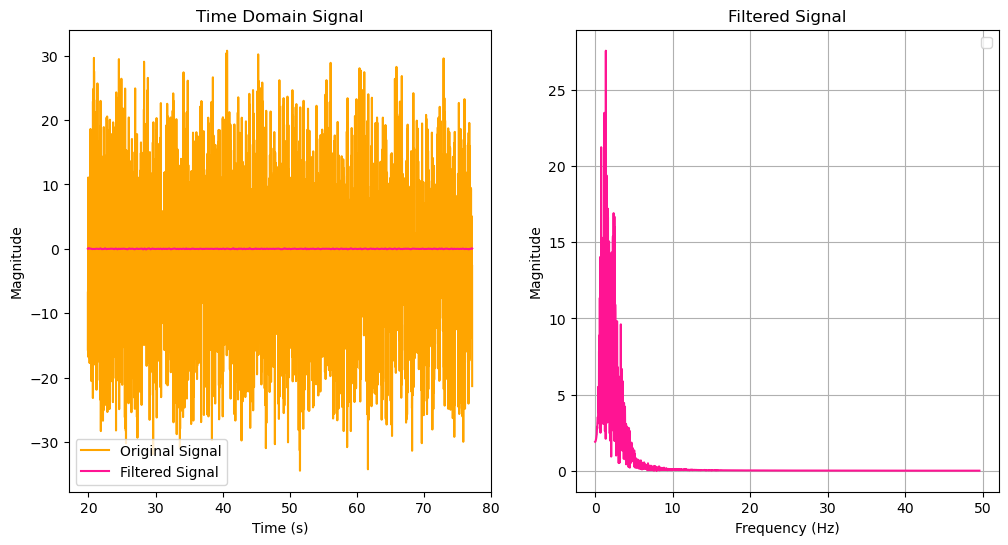

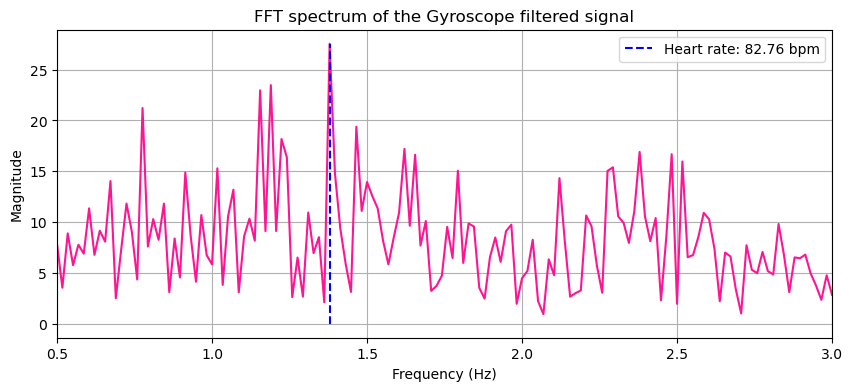

In [51]:
fs = meanfreq_ch       # dataset mean frequency
lowcut = 0.6          # Hz
highcut = 3.0         # Hz

# filter Butterworth bandpass
b_band, a_band = signal.butter(
    N=2,
    Wn=(lowcut, highcut),
    btype="bandpass",
    fs=fs
)

# The input of the filter is the temporal signal, not the FFT, and then we can compare the values 
filtered_signal = signal.filtfilt(b_band, a_band, ch['MagGyro'].values)


# Now performing the FFT on the filtered signal to check if the peak is more evident and if the bpm estimation is more accurate
fft_vals = np.fft.rfft(filtered_signal)
freqs = np.fft.rfftfreq(len(filtered_signal), d=1/fs)

fft_mag = np.abs(fft_vals)


#Visualization
fig, ax = plt.subplots(1,2,figsize=(12, 6))
ax1,ax2=ax[0],ax[1]


ax1.plot(ch['Time'], ch['MagAcc'], label='Original Signal', color='orange')
ax1.plot(ch['Time'], filtered_signal, label='Filtered Signal', color='deeppink')
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Magnitude")
ax1.set_title("Time Domain Signal")
ax1.legend()


ax2.plot(freqs, fft_mag,color='deeppink')

ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Magnitude")
ax2.set_title("Filtered Signal")
ax2.legend()
plt.grid()
plt.show()

plt.figure(figsize=(10,4))
plt.plot(freqs, fft_mag,color='deeppink')
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("FFT spectrum of the Gyroscope filtered signal")
plt.xlim(0.5,3)
max_idx = np.argmax(fft_mag )
peak_freq = freqs[max_idx]
bpm = peak_freq * 60
plt.vlines(peak_freq, ymin=0, ymax=np.abs(fft_mag[max_idx]), color='blue', linestyle='--',label=f"Heart rate: {bpm:.2f} bpm")
plt.grid()
plt.legend()
plt.show()

## Heart Rate Estimation

In [47]:
min_dist = int(fs/2)  # Assuming a minimum heart rate of 40 bpm (0.67 Hz) and a maximum of 120 bpm (2 Hz)

peaks, properties = signal.find_peaks(
    filtered_signal,
    distance=min_dist,
    prominence=np.std(filtered_signal) * 0.3
)


peak_times = ch['Time'].values[peaks]

# Calculate the diference between the peaks
diference = np.diff(peak_times)

# # To convert to bpm 
bpm_inst = 60 / diference

C:\Users\andre\AppData\Local\Temp\ipykernel_10332\3978970162.py:20: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


<Figure size 640x480 with 0 Axes>

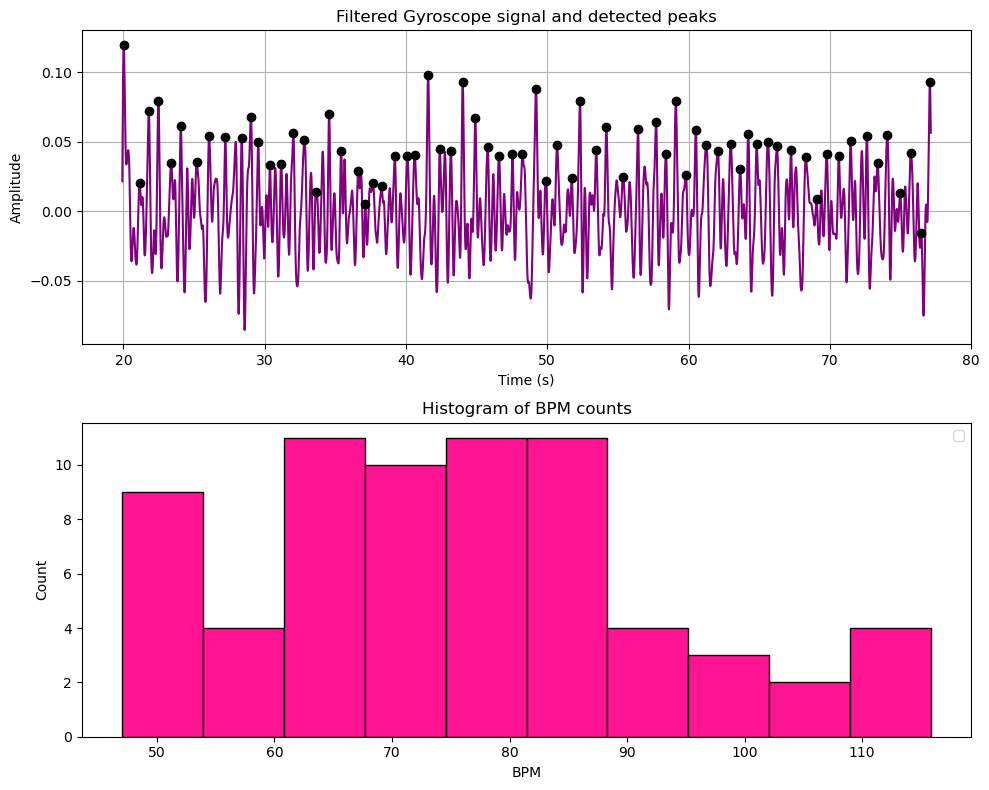

In [48]:
plt.figure()

fig, ax=plt.subplots(2,1, figsize=(10, 8))
ax1, ax2 = ax[0], ax[1]

# Filtered signal with detected peaks
ax1.plot(ch['Time'], filtered_signal, color='purple', label='Filtered signal')
ax1.plot(peak_times, filtered_signal[peaks], 'o', color='black', label='Peaks')
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Amplitude")
ax1.set_title("Filtered Gyroscope signal and detected peaks")
ax1.grid()
ax2.hist(bpm_inst, bins=10, color='deeppink',edgecolor='black')
ax2.set_xlabel("BPM")
ax2.set_ylabel("Count")
ax2.set_title("Histogram of BPM counts")



plt.legend()
plt.tight_layout()

Text(0, 0.5, 'Frequency')

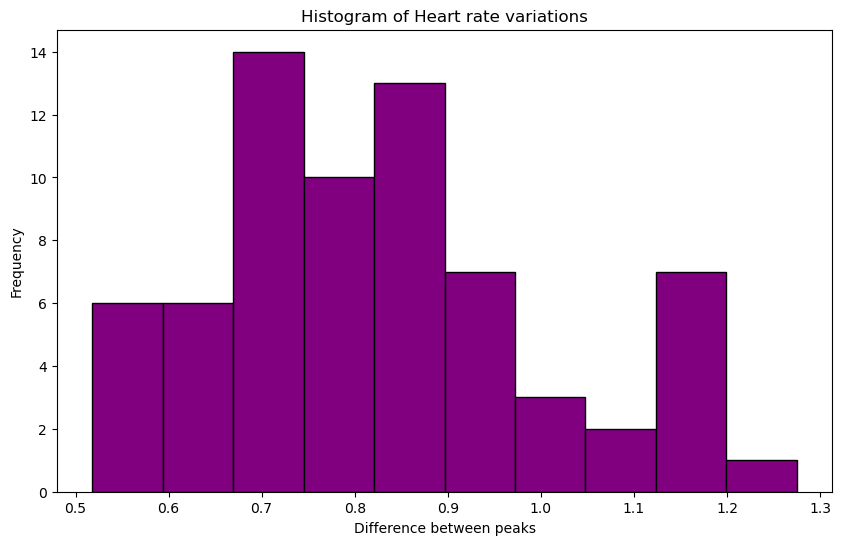

In [49]:
plt.figure(figsize=(10,6))
plt.hist(diference, bins=10, color='purple', edgecolor='black')
plt.title("Histogram of Heart rate variations")
plt.xlabel("Difference between peaks")
plt.ylabel("Frequency")

# Conclusions 

The tasks were performed on two datasets. The first one, related to Center Sternum medition on subject 1, while the second was selected based on the results of the preliminary statistical analysis; chest sweater dataset, of the individual 2, driven to the estimation of the heart rate of each one via multiple analysis and filters implementation. 

The statistical description showed similar patterns across both datasets, indicating comparable signal distributions and variability. From this analysis and following the consulted bibliography, the chosen variables to be object of the analysis are the acceleration, and gyroscope components.

After principal component analysis (PCA) analysis we decided to keep all the components for Center Sternum. Otherwise, in the Chest sweater, the acceleration components didn't showed high correlation, so for the Fourier analysis we only worked over the X axis.

The FFT analysis revealed dominant frequency peaks around 1.2–1.3 Hz in both datasets, corresponding to approximately 75 bpm, which lies within the expected physiological range (60–100 bpm). For the Chest sweater, the gyroscope provides a more accurate measurement in this case, giving a heart rate of 82.7bpm,  as it captures small rotational movements of the chest that are more directly related to the mechanical activity of the heart, while being less affected by larger linear motions such as breathing or loose fabric movement.

After applying bandpass filtering (0.6–3 Hz), the signal in the time domain got more clear as expected. Then the fourier transform for the analysis the relevant peaks became more pronounced, improving the clarity and reliability of heart rate estimation.



# Bibliography 

* Haescher, M., Matthies, D. J., Trimpop, J., & Urban, B. (2015, June). A study on measuring heart-and respiration-rate via wrist-worn accelerometer-based seismocardiography (SCG) in comparison to commonly applied technologies. In Proceedings of the 2nd international Workshop on Sensor-based Activity Recognition and Interaction (pp. 1-6).

* Balali, P., Rabineau, J., Hossein, A., Tordeur, C., Debeir, O., & Van De Borne, P. (2022). Investigating cardiorespiratory interaction using ballistocardiography and seismocardiography—a narrative review. Sensors, 22(23), 9565.

* Belaish, E. (2022). Know your sensors: An introduction to inertial sensors. 221e. URL: https://www.221e.com/wp-content/uploads/2022/11/221e-Whitepaper-An-Introduction-to-Inertial-Sensors.pdf

* Zigliotto, W., & Belaish, E. (2022). 3 IMU sensor fusion troublemakers and how you can outsmart them. 221e. URL: https://www.221e.com/wp-content/uploads/2022/11/221e-Whitepaper-3-IMU-Sensor-Fusion-Troublemakers.pdf

* Inan, O. T., Migeotte, P. F., Park, K. S., Etemadi, M., Tavakolian, K., Casanella, R., ... & Di Rienzo, M. (2014). Ballistocardiography and seismocardiography: A review of recent advances. IEEE journal of biomedical and health informatics, 19(4), 1414-1427.

* https://pysdr.org/es/content-es/filters.html

* https://davrot.github.io/pytutorial/scipy/scipy.signal_butterworth/